# Long-running skills: explicit state, interrupts, checkpoints and branches

### Chapter 4, notebook 1 of 3

Chapter 3 ran a skill once: select it, compile its instructions, generate, verify,
repair. This notebook runs skills for a long time. A buyer is comparing homes in
three King County cities, Seattle, Bellevue and Kent. A coordinating skill
dispatches five specialised agents, collects their results, survives interruptions
and process failures, and branches when the buyer changes an assumption.

Every model response in this notebook comes from `openai/gpt-5.6-luna` through
OpenRouter: called live, or replayed from a recording of a live run. The data is real where noted (King County house sales, Zillow's Seattle
metro series) and illustrative where noted (hazard scores, insurance scenarios). The
analysis is a vehicle for the harness, not a valuation.

**What gets built, in order**

| § | Builds | Chapter section |
|---|---|---|
| 1 | The investigation, the agents, and the five things this chapter keeps apart | 4.1 |
| 2 | Tools over the data; the SKILL.state loop from the paper running the investigation; the same work with a growing transcript, for comparison | 4.2.1 |
| 3 | `HarnessKernel`: control points, middleware, `SemanticInterrupt`, recovery policy, execution states, pins, recovery by action effect | 4.2.2 |
| 4 | Durable checkpoints in SQLite; a process failure and a resume; audits of the recorded history | 4.2.3 |
| 5 | A shared checkpoint, three city branches, a suspended branch, and a sub-branch that reuses what is still valid | 4.2.3 |
| 6 | An approval boundary, an action journal and idempotency for a consequential action | 4.2.3 |
| 7 | What the run left behind: records, audits, usage | 4.2.3 |
| 8 | Replaying the recorded run: reproducing it, inspecting a step, locating the effect of a change | 4.2.3 |

**Paper and harness.** The per-step loop — the model sees the procedure *P*, the
state *Σ_t* and the latest observation *O_t*, returns a state patch and an action, and
the runtime validates and merges the patch and discards the reasoning — is from
*SKILL.state: Scalable Long-Horizon Agent Skills* (Badhe, Tiwari & Chung, 2026). This
notebook installs [`skill_state`](https://github.com/Nicolepcx/skill_state), an
independent reference implementation written for the book. Everything from section 3
onward — the kernel, middleware, interrupts, checkpoints, branches, artifact store and
journal — is harness code written in this notebook, not part of the paper.

**What a full run costs.** A few hundred model calls: three city branches, the
transcript comparison, a resume and a sub-branch. Section 7 reports the tokens used.
The notebook therefore starts in replay mode: it re-runs a reference recording of a
live run, with no API key and no model cost, and switches to live calls when you set
`RUN_MODE = "live"` (section 0 and section 8).

In [ ]:
%pip install -q gdown openai pyyaml pandas numpy matplotlib python-dotenv

import importlib, os, subprocess, sys

SKILL_STATE_REPO = "https://github.com/Nicolepcx/skill_state"
try:
    import skill_state
except ModuleNotFoundError:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{SKILL_STATE_REPO}"],
                       capture_output=True, text=True)
    if r.returncode != 0:                      # repository without pyproject.toml: use a clone
        if not os.path.isdir("/tmp/skill_state_src"):
            subprocess.run(["git", "clone", "-q", "--depth", "1", SKILL_STATE_REPO,
                            "/tmp/skill_state_src"], check=True)
        sys.path.insert(0, "/tmp/skill_state_src")
    importlib.invalidate_caches()
    import skill_state
print("skill_state from", skill_state.__file__)

skill_state from /usr/local/lib/python3.13/dist-packages/skill_state/__init__.py


## 0. Setup

The data and the skill files come from a shared Drive folder, the same delivery
Chapter 3 uses. `ch04_data` holds the evidence the agents query; `ch04_skills` holds
the identity, the project facts, six skills and the investigation's state schema.

The model client implements `skill_state`'s `LLM` protocol (`complete`) and adds
`start`, which returns a running generation the kernel in section 3 reads while it
arrives and can stop early. Every call gets its own usage row.

**How to run this notebook**

1. **Replay first** (`RUN_MODE = "replay"`, the default). The notebook re-runs a
   reference recording of one live run, distributed with the book's assets in the
   Drive folder's `ch04_replay`. No API key, no model cost. Everything except the
   model runs for real: the tools, the kernel, the store, the injected faults. Every
   checkpoint, interrupt, branch and recovery in the notebook is produced in front of
   you; only the model's responses come from the recording.
2. **Then live** (`RUN_MODE = "live"`). Real calls to `openai/gpt-5.6-luna` through
   OpenRouter, about a hundred and fifty to two hundred of them for the whole notebook.
   Your run is recorded to `ch04_recordings/nb1_latest.jsonl`, and you can replay it
   afterwards.

A replay re-runs one recorded investigation. It cannot stand in for a new one. It
needs a recording made with this notebook version and these data and skill files,
and the setup cell refuses any other recording before anything runs. Change the
constraints, a skill or the harness code, and the replay stops at the first model
call whose prompt differs; from there on only a live run can say what the model
would do.

In [ ]:
import getpass, hashlib, inspect, json, re, shutil, sqlite3, textwrap, time, uuid
from dataclasses import dataclass, field
from enum import Enum
from pathlib import Path
from typing import Any, Callable, Dict, Iterator, List, Optional, Tuple

import gdown
import numpy as np
import openai
import pandas as pd
import yaml

from skill_state import (LLMResult, ParseError, Skill, SkillStateRuntime, build_prompt,
                         merge, parse_response, validate)

RUN_MODE = "live"   # "replay": re-run the reference recording, no API key, no model cost.
                      # "live": real model calls through OpenRouter, each one recorded.
REPLAY_FILE = None    # for replay; default: this session's latest recording, else the reference on Drive
NOTEBOOK_VERSION = "ch04-nb1/2026-10-31"   # a recording replays only with the version that made it

DRIVE_FOLDER_URL = ("https://drive.google.com/drive/folders/"
                    "1_zFkQWD8Mjyv_K5cCjMT2w7QTH2ttu1I?usp=sharing")
WORK = Path("ch04_work").resolve()
shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir(parents=True)

kwargs = {"url": DRIVE_FOLDER_URL, "output": str(WORK), "quiet": True, "use_cookies": False}
if "remaining_ok" in inspect.signature(gdown.download_folder).parameters:
    kwargs["remaining_ok"] = True
if not gdown.download_folder(**kwargs):
    raise RuntimeError("Nothing downloaded; is the Drive folder shared with 'Anyone with the link'?")

DATA = next(p for p in WORK.rglob("ch04_data") if p.is_dir())
SKILLS = next(p for p in WORK.rglob("ch04_skills") if p.is_dir())
for folder in (DATA, SKILLS):
    print(folder.name)
    for p in sorted(folder.iterdir()):
        print(f"   {p.name:46}{p.stat().st_size:>10,} bytes")

# --- model access -------------------------------------------------------------------
try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(), override=False)
except Exception:
    pass
if RUN_MODE == "live" and not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass.getpass("OpenRouter API key: ")

MODEL = "openai/gpt-5.6-luna"
BASE_URL = "https://openrouter.ai/api/v1"
USAGE: List[Dict[str, Any]] = []          # one row per model call, including calls stopped early
RECORDER = None                           # set below in live mode
_CALL_IDS = iter(range(1, 10**9))


class Generation:
    """One streamed model call. Iterate it for text pieces. `record` is this call's usage row;
    it is completed and logged once, when the stream ends or is closed early.

    Usage comes from the provider when the stream runs to the end. A stream closed early ends
    before the provider's usage chunk arrives, so its tokens are estimated from characters
    and marked as estimated; the provider may still bill for tokens generated after the close.
    `generation_id` lets section 7 ask the provider for the billed figures."""

    def __init__(self, client, model: str, label: str, prompt: str):
        self.record = {"call": next(_CALL_IDS), "label": label, "model": model, "execution_id": None,
                       "generation_id": None, "prompt_chars": len(prompt), "replayed": False}
        self._prompt, self._parts, self._usage, self._t0 = prompt, [], None, time.perf_counter()
        self._finished, self._complete = False, False
        self._resp = client.chat.completions.create(
            model=model, stream=True, stream_options={"include_usage": True},
            messages=[{"role": "user", "content": prompt}])
        self._gen = self._pieces()

    def _pieces(self) -> Iterator[str]:
        try:
            for chunk in self._resp:
                self.record["generation_id"] = self.record["generation_id"] or getattr(chunk, "id", None)
                if getattr(chunk, "usage", None):
                    self._usage = chunk.usage
                if chunk.choices and chunk.choices[0].delta and chunk.choices[0].delta.content:
                    self._parts.append(chunk.choices[0].delta.content)
                    yield self._parts[-1]
            self._complete = True
        finally:
            self._finish()

    def __iter__(self) -> Iterator[str]:
        return self._gen

    def close(self) -> None:
        self._gen.close()
        self._finish()                      # also covers a stream closed before its first piece

    def _finish(self) -> None:
        if self._finished:
            return
        self._finished = True
        self._resp.close()                  # closing the HTTP response stops the generation
        text, u = "".join(self._parts), self._usage
        self.record.update({
            "prompt_tokens": getattr(u, "prompt_tokens", None) or len(self._prompt) // 4,
            "completion_tokens": getattr(u, "completion_tokens", None) or len(text) // 4,
            "usage_source": "provider" if u else "estimated", "aborted": not self._complete,
            "completion_chars": len(text), "seconds": round(time.perf_counter() - self._t0, 2)})
        USAGE.append(self.record)
        if RECORDER:
            RECORDER.write(self.record, self._prompt, text)


class OpenRouterLLM:
    """skill_state's LLM protocol (`complete`) plus `start`, which the kernel uses to read
    the output while it is generated and to stop it early."""

    def __init__(self, model: str = MODEL, label: str = "unlabelled"):
        self.model, self.label = model, label
        self.client = openai.OpenAI(api_key=os.environ["OPENROUTER_API_KEY"], base_url=BASE_URL)

    def with_label(self, label: str) -> "OpenRouterLLM":
        other = OpenRouterLLM.__new__(OpenRouterLLM)
        other.model, other.label, other.client = self.model, label, self.client
        return other

    def start(self, prompt: str) -> Generation:
        return Generation(self.client, self.model, self.label, prompt)

    def complete(self, prompt: str) -> LLMResult:
        g = self.start(prompt)
        text = "".join(g)
        return LLMResult(text, g.record["prompt_tokens"], g.record["completion_tokens"])


def provider_usage(generation_id: str, attempts: int = 3) -> Optional[Dict[str, Any]]:
    """The provider's own record of a generation (OpenRouter `GET /generation?id=`)."""
    import requests
    for i in range(attempts):
        try:
            r = requests.get(f"{BASE_URL}/generation", params={"id": generation_id}, timeout=20,
                             headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"})
            if r.ok:
                return r.json().get("data")
        except requests.RequestException:
            pass
        time.sleep(2 * (i + 1))             # the record can take a moment to appear
    return None

ch04_data
   SOURCES.md                                         1,760 bytes
   hazard_profiles_illustrative.csv                   1,073 bytes
   insurance_scenarios_illustrative.csv                 808 bytes
   king_county_sales_2014_2015.csv                2,326,367 bytes
   zillow_forecast_seattle_metro.csv                    148 bytes
   zillow_market_heat_seattle_metro.csv               1,569 bytes
   zillow_zhvi_seattle_metro.csv                      9,434 bytes
   zipcode_city.csv                                   1,028 bytes
ch04_skills
   AGENTS.md                                          1,403 bytes
   PROJECT.md                                         1,146 bytes
   home-purchase-research-state-schema.json           2,407 bytes
   skill-environmental-risk.md                          930 bytes
   skill-home-purchase-research.md                    2,492 bytes
   skill-insurance-finance.md                         1,225 bytes
   skill-market-research.md                           

The recorder writes a header first: the notebook version and a digest of every data
and skill file. Then it writes one JSON line per model call, as each call ends, so a
run that fails halfway still leaves its recording. Each line holds the usage row, the
exact prompt, and the response text exactly as the API returned it.

The replay client serves a recorded response only for a prompt identical to the
recorded one, matched by its label and a digest of its text. If the harness ever
produces a prompt the recording does not contain, the replay stops with
`ReplayDivergence` and shows how that prompt differs from the one the recording
expected next.

In [ ]:
import difflib
from collections import defaultdict, deque
from contextlib import contextmanager

RECORDINGS = Path("ch04_recordings").resolve()
RECORDINGS.mkdir(exist_ok=True)


def prompt_digest(prompt: str) -> str:
    return hashlib.sha256(prompt.encode()).hexdigest()[:16]


def input_fingerprint() -> Dict[str, Any]:
    """What a recording depends on besides the harness code: the notebook version, the model,
    and every data and skill file, by digest."""
    files = {f"{d.name}/{p.name}": hashlib.sha256(p.read_bytes()).hexdigest()[:16]
             for d in (DATA, SKILLS) for p in sorted(d.iterdir()) if p.is_file()}
    return {"notebook": NOTEBOOK_VERSION, "model": MODEL, "files": files}


class Recorder:
    """A header line with the input fingerprint, then one JSON line per model call: its usage
    row, the exact prompt, and the response text exactly as the API returned it."""

    def __init__(self, path: Path):
        self.path, self.count = path, 0
        self.file = path.open("w")
        self.file.write(json.dumps({"kind": "header", **input_fingerprint()}) + "\n")
        self.file.flush()

    def write(self, record: Dict, prompt: str, text: str):
        row = {**record, "prompt_digest": prompt_digest(prompt), "prompt": prompt, "text": text}
        self.file.write(json.dumps(row) + "\n")
        self.file.flush()
        self.count += 1


def read_recording(path: Path) -> Tuple[Dict, List[Dict]]:
    rows = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
    header = rows[0] if rows and rows[0].get("kind") == "header" else {}
    return header, [r for r in rows if r.get("kind") != "header"]


def load_recording(path: Path) -> List[Dict]:
    return read_recording(path)[1]


def incompatibilities(header: Dict) -> List[str]:
    """Why a recording cannot be replayed with this notebook and these files, if it cannot."""
    now = input_fingerprint()
    if not header:
        return ["the recording has no header"]
    out = []
    if header.get("notebook") != now["notebook"]:
        out.append(f"made by notebook version {header.get('notebook')}, this is {now['notebook']}")
    for name in sorted(set(header.get("files", {})) | set(now["files"])):
        if header.get("files", {}).get(name) != now["files"].get(name):
            out.append(f"{name} differs from the file the recording was made with")
    return out


class ReplayDivergence(Exception):
    """The harness produced a prompt that the recorded run never sent."""

    def __init__(self, label: str, prompt: str, expected: Optional[Dict], reason: Optional[str] = None):
        self.label, self.prompt, self.expected = label, prompt, expected
        if reason:
            self.diff = [reason]
        elif expected is None:
            self.diff = ["(the recording has no further call with this label)"]
        else:
            self.diff = [l.rstrip("\n") for l in difflib.unified_diff(
                expected["prompt"].splitlines(), prompt.splitlines(),
                f"recorded call {expected['call']}", "this run", n=1, lineterm="")]
        super().__init__(f"replay diverged at '{label}': " + (reason or "the prompt was never recorded"))


class ReplayGeneration:
    """Plays one recorded response back in pieces, through the same interface as Generation.
    A recorded call the harness stopped early must be stopped early again, and vice versa;
    otherwise the replay is not reproducing the run."""

    def __init__(self, rec: Dict, label: str, prompt: str, piece: int = 40):
        self.rec, self.text = rec, rec["text"]
        self.record = {"call": next(_CALL_IDS), "label": label, "model": rec["model"], "execution_id": None,
                       "generation_id": rec.get("generation_id"), "prompt_chars": len(prompt),
                       "replayed": True, "recorded_call": rec["call"]}
        self._finished, self._exhausted = False, False
        self._gen = self._pieces(piece)

    def _pieces(self, n: int) -> Iterator[str]:
        for i in range(0, len(self.text), n):
            yield self.text[i:i + n]
        self._exhausted = True

    def __iter__(self):
        return self._gen

    def close(self):
        self._gen.close()
        if self._finished:
            return
        self._finished = True
        stopped_early = not self._exhausted
        self.record.update({"prompt_tokens": self.rec["prompt_tokens"],
                            "completion_tokens": self.rec["completion_tokens"], "usage_source": "recorded",
                            "aborted": stopped_early, "completion_chars": len(self.text), "seconds": 0.0})
        USAGE.append(self.record)
        if stopped_early != self.rec["aborted"]:
            raise ReplayDivergence(self.record["label"], "", self.rec, reason=(
                f"recorded call {self.rec['call']} was {'stopped early' if self.rec['aborted'] else 'completed'}; "
                f"in this replay it was {'stopped early' if stopped_early else 'completed'}"))


class ReplayLLM:
    """Serves recorded responses to identical prompts. Each instance consumes its own copy."""

    def __init__(self, calls: List[Dict], labels: Optional[set] = None, label: str = "unlabelled", _q=None):
        self.label, self.calls = label, calls
        self.model = calls[0]["model"] if calls else MODEL
        if _q is None:
            _q = {"exact": defaultdict(deque), "by_label": defaultdict(deque), "served": [0]}
            for c in calls:
                if labels is None or c["label"] in labels:
                    _q["exact"][(c["label"], c["prompt_digest"])].append(c)
                    _q["by_label"][c["label"]].append(c)
        self._q = _q

    def with_label(self, label: str) -> "ReplayLLM":
        return ReplayLLM(self.calls, label=label, _q=self._q)

    def start(self, prompt: str) -> ReplayGeneration:
        hits = self._q["exact"].get((self.label, prompt_digest(prompt)))
        if not hits:
            pending = self._q["by_label"].get(self.label)
            raise ReplayDivergence(self.label, prompt, pending[0] if pending else None)
        rec = hits.popleft()
        self._q["by_label"][self.label].remove(rec)
        self._q["served"][0] += 1
        return ReplayGeneration(rec, self.label, prompt)

    def complete(self, prompt: str) -> LLMResult:
        g = self.start(prompt)
        text = "".join(g)
        g.close()
        return LLMResult(text, g.record["prompt_tokens"], g.record["completion_tokens"])

    def unserved(self) -> int:
        return sum(len(q) for q in self._q["by_label"].values())


@contextmanager
def using_llm(other):
    """Temporarily route every kernel built inside the block to another model client."""
    global llm
    previous, llm = llm, other
    try:
        yield other
    finally:
        llm = previous


if RUN_MODE == "live":
    RECORDING_PATH = RECORDINGS / "nb1_latest.jsonl"
    RECORDER = Recorder(RECORDING_PATH)
    llm = OpenRouterLLM()
elif RUN_MODE == "replay":
    candidates = [Path(REPLAY_FILE)] if REPLAY_FILE else \
        [RECORDINGS / "nb1_latest.jsonl", *sorted(WORK.rglob("nb1_recording.jsonl"))]
    RECORDING_PATH = next((p for p in candidates if p.exists()), None)
    if RECORDING_PATH is None:
        raise FileNotFoundError(
            "Replay needs a recording made by this notebook, and none was found: not in ch04_recordings/ "
            "and not in the Drive folder's ch04_replay/. Set RUN_MODE = 'live' to make one.")
    header, calls = read_recording(RECORDING_PATH)
    problems = incompatibilities(header)
    if problems:
        raise RuntimeError("This recording cannot be replayed here. A replay re-runs one recorded "
                           "investigation; it cannot stand in for a different one.\n  - " + "\n  - ".join(problems)
                           + "\nUse a recording made with this notebook and these files, or set RUN_MODE = 'live'.")
    llm = ReplayLLM(calls)
    MODEL = llm.model
else:
    raise ValueError(f"RUN_MODE must be 'live' or 'replay', not {RUN_MODE!r}")
print(f"mode: {RUN_MODE}   model: {MODEL}   recording: {RECORDING_PATH}")

mode: live   model: openai/gpt-5.6-luna   recording: /content/ch04_recordings/nb1_latest.jsonl


In [ ]:
# --- Chapter 3's artifact parser and surface compiler, unchanged in behaviour --------
_FRONTMATTER = re.compile(r"\A---\n(.*?)\n---\n?", re.S)
_SECTION = re.compile(r"^<!--\s*section:\s*([\w.\-]+)\s*-->\s*$", re.M)
KIND_PRECEDENCE = ("identity", "project", "skill", "persona")


@dataclass(frozen=True)
class Artifact:
    kind: str
    name: str
    version: str
    path: Path
    meta: Dict
    sections: Dict[str, str]
    digest: str

    @property
    def always_loaded(self) -> bool:
        return bool(self.meta.get("always_loaded"))

    @property
    def owns(self) -> List[str]:
        return list(self.meta.get("owns") or [])

    @property
    def requires(self) -> Dict[str, List[str]]:
        """Capability requests (Chapter 3b). A request is never a grant."""
        return {k: list(v or []) for k, v in (self.meta.get("requires") or {}).items()}


def parse(path: Path) -> Artifact:
    raw = path.read_text(encoding="utf-8")
    m = _FRONTMATTER.match(raw)
    if not m:
        raise ValueError(f"{path.name}: no frontmatter")
    meta, body = yaml.safe_load(m.group(1)) or {}, raw[m.end():]
    marks = list(_SECTION.finditer(body))
    if not marks or body[:marks[0].start()].strip():
        raise ValueError(f"{path.name}: text outside a section")
    sections = {}
    for i, mark in enumerate(marks):
        end = marks[i + 1].start() if i + 1 < len(marks) else len(body)
        sections[mark.group(1)] = body[mark.end():end].strip()
    for missing in set(meta.get("owns") or []) - set(sections):
        raise ValueError(f"{path.name}: owns '{missing}' but has no such section")
    return Artifact(meta["artifact"], meta["name"], str(meta["version"]), path, meta, sections,
                    hashlib.sha256(raw.encode()).hexdigest()[:12])


def overlap(artifacts) -> Dict[str, List[str]]:
    claims: Dict[str, List[str]] = {}
    for a in artifacts:
        for s in a.owns:
            claims.setdefault(s, []).append(a.name)
    return {s: n for s, n in claims.items() if len(n) > 1}


@dataclass
class Surface:
    text: str
    manifest: Dict[str, Any]


def compile_surface(artifacts, facts: Optional[Dict[str, Any]] = None) -> Surface:
    """Identity, then project, then skill; repeated paragraphs kept once; a manifest of
    every section that went in, with its artifact version and digest."""
    clash = overlap(artifacts)
    if clash:
        raise ValueError(f"ambiguous surface: {clash}")
    blocks, seen, used = [], set(), []
    for a in sorted(artifacts, key=lambda a: KIND_PRECEDENCE.index(a.kind)):
        for sid, body in a.sections.items():
            kept = [p.strip() for p in re.split(r"\n\s*\n", body)
                    if p.strip() and re.sub(r"\s+", " ", p.lower()) not in seen]
            seen.update(re.sub(r"\s+", " ", p.lower()) for p in kept)
            if kept:
                blocks.append("\n\n".join(kept))
                used.append({"artifact": a.name, "version": a.version, "digest": a.digest,
                             "section": sid})
    if facts:
        blocks.append("## Facts supplied by the harness\n\n" +
                      "\n".join(f"- {k}: {v}" for k, v in facts.items()) +
                      "\n\nThese are given. Do not infer facts that are not listed.")
    text = "\n\n".join(blocks)
    return Surface(text, {"sections": used,
                          "surface_digest": hashlib.sha256(text.encode()).hexdigest()[:12]})


ARTIFACTS = {a.name: a for a in (parse(p) for p in sorted(SKILLS.glob("*.md")))}
ALWAYS = [a for a in ARTIFACTS.values() if a.always_loaded]

print(f"{'artifact':30}{'kind':10}{'version':9}{'digest':14}requests")
for a in ARTIFACTS.values():
    print(f"{a.name:30}{a.kind:10}{a.version:9}{a.digest:14}{', '.join(a.requires.get('tools', []))}")

artifact                      kind      version  digest        requests
home-research-agent           identity  1.0.0    4029c8ea0750  
seattle-home-investigation    project   1.0.0    c50e285baedc  
environmental-risk            skill     1.0.0    f5f4fe5d3bca  hazard_profile
home-purchase-research        skill     1.0.0    7b6ed39e6af3  dispatch_agent, create_branch, request_approval, submit_inquiry
insurance-finance             skill     1.0.0    965c6df4219f  insurance_scenarios, affordability
market-research               skill     1.0.0    98b66cff194a  query_sales, metro_value_series, market_heat, value_forecast
quantitative-analysis         skill     1.0.0    b813e9b72b4b  query_sales, metro_value_series, run_regression
synthesis                     skill     1.0.0    d7fe67bd3927  read_artifacts


## 1. Beyond a single execution

A buyer wants to compare buying in Seattle, Bellevue or Kent. They have a budget, a
down payment, an ownership horizon and a tolerance for risk, and they care about the
market, the price, natural hazards, insurance and what the home costs each month.

No single call can do this. A coordinating skill, `home-purchase-research`, owns the
investigation and dispatches five agents, each with its own skill:

| Agent | Skill | Returns |
|---|---|---|
| Market research | `market-research` | Metro trend, market heat, comparable sales within budget |
| Quantitative analysis | `quantitative-analysis` | A price model on comparable sales, a trend on the metro series, scenarios |
| Environmental risk | `environmental-risk` | Hazard scores, the material hazards, the cover they imply |
| Insurance and finance | `insurance-finance` | Insurance cost, monthly payment, an affordability verdict |
| Synthesis | `synthesis` | A comparison report with evidence gaps listed separately |

The work has three levels. The **objective** is the buyer's decision. A **branch** is
one line of investigation — one city, or one city under different assumptions. A
**step** is one model call inside a branch: the coordinator deciding what to do next,
or an agent calling a tool.

Running this for hours or days, across interruptions, needs five things kept apart.
The rest of the notebook builds each of them; section 7 shows where each one lives
after the run.

| | What it is | Lifetime | Where it lives here |
|---|---|---|---|
| **Skill definition** | The procedure *P*, versioned and hashed | Changes by release | The skill files from Drive |
| **Execution state** | *Σ*: what is true now in this branch | Changes every step | The latest checkpoint of an execution |
| **Observations and artifacts** | Tool results; the agents' outputs | Produced by steps | The artifact store, referenced from *Σ* by id |
| **Committed transitions** | Each validated *Σ*, and the action it led to | Append-only | The checkpoint table |
| **Operational evidence** | Interrupts, recoveries, actions, failures | Append-only, across executions | The event table and the action journal |

The skill definition is what the model reads. The execution state is what the model
updates. The other three are what the harness keeps so it can resume, audit and later
improve the skill. The model never reads them back.

In [ ]:
CITIES = ("Seattle", "Bellevue", "Kent")


def _wide_series(file: str) -> pd.Series:
    row = pd.read_csv(DATA / file).iloc[0]
    months = [c for c in row.index if c[:2] in ("19", "20")]
    s = pd.to_numeric(row[months])
    s.index = pd.to_datetime(months)
    return s.dropna()


SALES = (pd.read_csv(DATA / "king_county_sales_2014_2015.csv", dtype={"zipcode": str, "id": str},
                     parse_dates=["date"])
         .merge(pd.read_csv(DATA / "zipcode_city.csv", dtype={"zipcode": str}), on="zipcode"))
ZHVI = _wide_series("zillow_zhvi_seattle_metro.csv")
HEAT = _wide_series("zillow_market_heat_seattle_metro.csv")
_fc = pd.read_csv(DATA / "zillow_forecast_seattle_metro.csv").iloc[0]
FORECAST = {"base_date": _fc["BaseDate"],
            "growth_pct": {c: float(_fc[c]) for c in _fc.index if c[:2] == "20" and c != _fc["BaseDate"]}}
HAZARDS = pd.read_csv(DATA / "hazard_profiles_illustrative.csv")
INSURANCE = pd.read_csv(DATA / "insurance_scenarios_illustrative.csv")


def _evidence(file: str, as_of: str, illustrative: bool = False) -> Dict[str, Any]:
    return {"file": file, "as_of": as_of, "illustrative": illustrative,
            "sha256": hashlib.sha256((DATA / file).read_bytes()).hexdigest()[:16]}


# One provenance record per source. Artifacts record which of these they used, so a
# changed file can invalidate exactly the artifacts built on it.
EVIDENCE = {
    "king_county_sales": _evidence("king_county_sales_2014_2015.csv", str(SALES.date.max().date())),
    "zillow_zhvi": _evidence("zillow_zhvi_seattle_metro.csv", str(ZHVI.index.max().date())),
    "zillow_market_heat": _evidence("zillow_market_heat_seattle_metro.csv", str(HEAT.index.max().date())),
    "zillow_forecast": _evidence("zillow_forecast_seattle_metro.csv", FORECAST["base_date"]),
    "hazard_profiles": _evidence("hazard_profiles_illustrative.csv", "n/a", True),
    "insurance_scenarios": _evidence("insurance_scenarios_illustrative.csv", "n/a", True),
}

print(f"{'source':22}{'as of':13}{'illustrative':14}sha256")
for name, e in EVIDENCE.items():
    print(f"{name:22}{e['as_of']:13}{str(e['illustrative']):14}{e['sha256']}")
print("\nsales per city:", SALES[SALES.city.isin(CITIES)].city.value_counts().to_dict())
print(f"metro value {ZHVI.index[0].date()} .. {ZHVI.index[-1].date()}: "
      f"{ZHVI.iloc[0]:,.0f} -> {ZHVI.iloc[-1]:,.0f} USD")
print("forecast:", FORECAST)

source                as of        illustrative  sha256
king_county_sales     2015-05-27   False         41f29fcc3d0e9696
zillow_zhvi           2026-09-30   False         22a7e430bbba0dbf
zillow_market_heat    2026-09-30   False         786d8de4a0298d7d
zillow_forecast       2026-09-30   False         7cb3f9b1cf073df7
hazard_profiles       n/a          True          2620338a43eab80c
insurance_scenarios   n/a          True          ded6fbd62fce3d94

sales per city: {'Seattle': 8977, 'Bellevue': 1407, 'Kent': 1203}
metro value 2000-01-31 .. 2026-09-30: 220,218 -> 720,147 USD
forecast: {'base_date': '2026-09-30', 'growth_pct': {'2026-10-31': -0.1, '2026-12-31': -0.6, '2027-09-30': 0.0}}


## 2. Explicit execution state

### 2.1 Tools: the arithmetic happens in Python

The agents never compute a number in their reasoning. They call tools, and the tools
do the work with pandas and numpy: a hedonic regression of log price on size, grade,
condition, age and city; a linear trend on the metro value series; a mortgage payment.
Each tool returns a small summary, not the raw data, so an observation stays bounded.

Each tool also declares which evidence it reads. When an agent's artifact is stored,
the harness records those sources with their digests, which is what lets section 5
decide later which artifacts are still valid.

The insurance tool talks to a data service that can go down. `SERVICE_DOWN` holds the
regions whose feed is not responding; while any region is down, the King County
average is unavailable too, because it is computed from the regional feeds.

In [ ]:
class ToolUnavailable(Exception):
    """An external data source did not respond."""


SERVICE_DOWN: set = set()          # regions whose insurance feed is not responding
RATE_LIMITED: set = set()          # tools whose service answers every request with HTTP 429


class RateLimited(Exception):
    """A service refused the request for now. Not an outage: the harness does not suspend for it."""


def _check_rate_limit(tool: str) -> None:
    if tool in RATE_LIMITED:
        raise RateLimited(f"{tool}: HTTP 429 Too Many Requests. Retry the request.")
ILLUSTRATIVE_RATE_PCT = 6.5        # mortgage rate assumption for the payment tool


def _records(df: pd.DataFrame) -> List[Dict[str, Any]]:
    return json.loads(df.to_json(orient="records"))


def _check_city(city: str) -> None:
    if city not in CITIES:
        raise ValueError(f"unknown city '{city}'; use one of {list(CITIES)}")


def _est_value_today(d: pd.DataFrame) -> np.ndarray:
    """2014-15 sale price scaled by the metro value index from the sale month to now."""
    at_sale = ZHVI.reindex(d["date"] + pd.offsets.MonthEnd(0)).to_numpy()
    return d["price"].to_numpy() * float(ZHVI.iloc[-1]) / at_sale


def query_sales(city: str, budget_usd: Optional[float] = None) -> Dict[str, Any]:
    _check_city(city)
    d = SALES[SALES.city == city].copy()
    d["est_value_today"] = _est_value_today(d)
    within = d[d.est_value_today <= budget_usd] if budget_usd else d.iloc[0:0]
    examples = within.nlargest(5, "est_value_today")[
        ["id", "bedrooms", "bathrooms", "sqft_living", "grade", "yr_built", "est_value_today"]].round(0)
    return {"city": city, "sales_2014_2015": int(len(d)),
            "median_price_2014_2015_usd": int(d.price.median()),
            "median_est_value_today_usd": int(d.est_value_today.median()),
            "est_value_method": "2014-15 price scaled by the Seattle-metro value index; metro-level estimate",
            "budget_usd": budget_usd,
            "comparables_within_budget": int(len(within)) if budget_usd else None,
            "median_est_value_within_budget_usd": int(within.est_value_today.median()) if len(within) else None,
            "examples_closest_to_budget": _records(examples)}


def metro_value_series() -> Dict[str, Any]:
    s = ZHVI
    five_years_ago = s[s.index <= s.index[-1] - pd.DateOffset(years=5)].iloc[-1]
    return {"region": "Seattle metro", "as_of": str(s.index[-1].date()),
            "latest_usd": int(s.iloc[-1]), "value_2014_05_usd": int(s.loc["2014-05-31"]),
            "peak": {"date": str(s.idxmax().date()), "value_usd": int(s.max())},
            "change_since_peak_pct": round(100 * (s.iloc[-1] / s.max() - 1), 1),
            "change_5y_pct": round(100 * (s.iloc[-1] / five_years_ago - 1), 1)}


def market_heat(months: int = 24) -> Dict[str, Any]:
    _check_rate_limit("market_heat")
    s = HEAT.iloc[-int(months):]
    return {"region": "Seattle metro", "as_of": str(s.index[-1].date()), "latest": float(s.iloc[-1]),
            "mean_last_12": round(float(HEAT.iloc[-12:].mean()), 1),
            "change_12m": float(HEAT.iloc[-1] - HEAT.iloc[-13]),
            "trend_per_month": round(float(np.polyfit(np.arange(len(s)), s.to_numpy(), 1)[0]), 2),
            "window_min": float(s.min()), "window_max": float(s.max())}


def value_forecast() -> Dict[str, Any]:
    return {"region": "Seattle metro", "publisher": "Zillow", **FORECAST}


def run_regression(model: str, horizon_years: int = 10, window_start: str = "2012-01-31",
                   window_end: Optional[str] = None) -> Dict[str, Any]:
    if model == "hedonic":
        d = SALES[SALES.city.isin(CITIES)]
        X = np.column_stack([np.ones(len(d)), np.log(d.sqft_living), d.grade, d.condition,
                             2015 - d.yr_built, (d.city == "Bellevue").astype(float),
                             (d.city == "Kent").astype(float)])
        y = np.log(d.price.to_numpy())
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        resid = y - X @ beta
        names = ["intercept", "log_sqft_living", "grade", "condition", "age_years",
                 "city_Bellevue", "city_Kent"]
        return {"model": "hedonic", "target": "log(price), 2014-15 sales", "n": int(len(d)),
                "coefficients": {n: round(float(b), 4) for n, b in zip(names, beta)},
                "city_effect_vs_Seattle_pct": {c: round(100 * (np.exp(beta[i]) - 1), 1)
                                               for c, i in (("Bellevue", 5), ("Kent", 6))},
                "r2": round(float(1 - resid.var() / y.var()), 3),
                "residual_sd_log": round(float(resid.std()), 3)}
    if model == "trend":
        s = ZHVI[window_start:window_end]
        t = ((s.index - s.index[0]).days / 365.25).to_numpy()
        slope, intercept = np.polyfit(t, s.to_numpy(), 1)
        fitted = intercept + slope * t
        r2 = 1 - ((s.to_numpy() - fitted) ** 2).sum() / ((s.to_numpy() - s.mean()) ** 2).sum()
        latest, t_latest = float(ZHVI.iloc[-1]), (ZHVI.index[-1] - s.index[0]).days / 365.25
        g12 = list(FORECAST["growth_pct"].values())[-1]
        h = int(horizon_years)
        return {"model": "linear_trend", "series": "Seattle-metro typical home value",
                "window": [str(s.index[0].date()), str(s.index[-1].date())],
                "slope_usd_per_year": int(slope), "r2": round(float(r2), 3), "horizon_years": h,
                "scenarios_usd_at_horizon": {
                    "trend_continues": int(intercept + slope * (t_latest + h)),
                    "flat": int(latest),
                    "published_12m_forecast_carried_forward": int(latest * (1 + g12 / 100) ** h)},
                "label": "scenarios under stated assumptions, not predictions"}
    raise ValueError("model must be 'hedonic' or 'trend'")


def hazard_profile(city: str) -> Dict[str, Any]:
    _check_city(city)
    return {"city": city, "source": "illustrative table",
            "hazards": _records(HAZARDS[HAZARDS.city == city][["hazard", "score_0_100", "notes"]])}


def insurance_scenarios(region: str) -> Dict[str, Any]:
    if region in SERVICE_DOWN or (region == "King County" and SERVICE_DOWN):
        raise ToolUnavailable(f"insurance data service: request for '{region}' timed out "
                              "(HTTP 503 Service Unavailable). The request may succeed if retried.")
    rows = INSURANCE[INSURANCE.region == region]
    if rows.empty:
        raise ValueError(f"unknown region '{region}'; use one of {sorted(INSURANCE.region.unique())}")
    return {"region": region, "source": "illustrative table",
            "scenarios": _records(rows.drop(columns="region"))}


def affordability(price_usd: float, down_payment_pct: float, annual_insurance_usd: float,
                  budget_usd: Optional[float] = None, rate_pct: float = ILLUSTRATIVE_RATE_PCT,
                  years: int = 30, property_tax_pct: float = 1.0) -> Dict[str, Any]:
    loan = price_usd * (1 - down_payment_pct / 100)
    r, n = rate_pct / 1200, years * 12
    pi = loan * r / (1 - (1 + r) ** -n)
    tax, ins = price_usd * property_tax_pct / 1200, annual_insurance_usd / 12
    return {"price_usd": round(price_usd), "down_payment_usd": round(price_usd - loan),
            "loan_usd": round(loan), "rate_pct": rate_pct, "rate_note": "illustrative rate",
            "monthly_principal_interest_usd": round(pi), "monthly_property_tax_usd": round(tax),
            "monthly_insurance_usd": round(ins), "monthly_total_usd": round(pi + tax + ins),
            "price_to_budget_pct": round(100 * price_usd / budget_usd, 1) if budget_usd else None}


@dataclass(frozen=True)
class Tool:
    fn: Optional[Callable]
    reads: Tuple[str, ...]          # evidence names, recorded as artifact inputs
    doc: str                        # what the agent is told the tool does


TOOLS: Dict[str, Tool] = {
    "query_sales": Tool(query_sales, ("king_county_sales", "zillow_zhvi"),
                        "2014-15 sales in a city, their estimated value today, and comparables within budget"),
    "metro_value_series": Tool(metro_value_series, ("zillow_zhvi",),
                               "Seattle-metro typical home value: latest, 2014, peak, 5-year change"),
    "market_heat": Tool(market_heat, ("zillow_market_heat",),
                        "Seattle-metro market heat index over the last `months` months"),
    "value_forecast": Tool(value_forecast, ("zillow_forecast",),
                           "Zillow's published 1, 3 and 12-month value forecast for the Seattle metro"),
    "run_regression": Tool(run_regression, ("king_county_sales", "zillow_zhvi", "zillow_forecast"),
                           "model='hedonic': log price on size, grade, condition, age and city; "
                           "model='trend': linear trend on the metro series with scenarios at the horizon"),
    "hazard_profile": Tool(hazard_profile, ("hazard_profiles",), "hazard scores 0-100 for a city"),
    "insurance_scenarios": Tool(insurance_scenarios, ("insurance_scenarios",),
                                "insurance premiums and coverage for a region: a city, or 'King County'"),
    "affordability": Tool(affordability, (), "monthly cost of a purchase: principal and interest, tax, insurance"),
    "read_artifacts": Tool(None, (), "the content of artifacts in this branch, by id"),
}


def tool_usage(name: str) -> str:
    """How the agent is told to call a tool: its signature and one line on what it returns."""
    sig = "ids: list of artifact ids" if name == "read_artifacts" else ", ".join(
        p.name if p.default is inspect.Parameter.empty else f"{p.name}={p.default!r}"
        for p in inspect.signature(TOOLS[name].fn).parameters.values())
    return f"{name}({sig}): {TOOLS[name].doc}"


def run_tool(name: str, args: Dict[str, Any], read_artifacts: Optional[Callable] = None) -> Dict[str, Any]:
    if name not in TOOLS:
        raise ValueError(f"unknown tool '{name}'")
    if name == "read_artifacts":
        return read_artifacts(list(args.get("ids", [])))
    try:
        inspect.signature(TOOLS[name].fn).bind(**args)
    except TypeError as e:
        raise ValueError(f"bad arguments ({e}). Usage: {tool_usage(name)}") from None
    return TOOLS[name].fn(**args)


def compact(result: Any, limit: int = 1800) -> str:
    text = json.dumps(result, separators=(",", ":"), default=str)
    return text if len(text) <= limit else text[:limit] + "...(truncated)"

In [ ]:
# The tools on their own, before any model is involved.
for name, args in [("metro_value_series", {}),
                   ("query_sales", {"city": "Kent", "budget_usd": 850000}),
                   ("run_regression", {"model": "trend", "horizon_years": 10}),
                   ("run_regression", {"model": "hedonic"}),
                   ("hazard_profile", {"city": "Kent"})]:
    print(f"{name}({args})\n   {compact(run_tool(name, args), 600)}\n")

metro_value_series({})
   {"region":"Seattle metro","as_of":"2026-09-30","latest_usd":720147,"value_2014_05_usd":315667,"peak":{"date":"2022-06-30","value_usd":762709},"change_since_peak_pct":-5.6,"change_5y_pct":9.8}

query_sales({'city': 'Kent', 'budget_usd': 850000})
   {"city":"Kent","sales_2014_2015":1203,"median_price_2014_2015_usd":283200,"median_est_value_today_usd":626671,"est_value_method":"2014-15 price scaled by the Seattle-metro value index; metro-level estimate","budget_usd":850000,"comparables_within_budget":1052,"median_est_value_within_budget_usd":604557,"examples_closest_to_budget":[{"id":"8856500220","bedrooms":3,"bathrooms":3.0,"sqft_living":2760,"grade":9,"yr_built":1991,"est_value_today":849932.0},{"id":"2380000190","bedrooms":3,"bathrooms":2.0,"sqft_living":2530,"grade":7,"yr_built":1977,"est_value_today":849932.0},{"id":"8562890370","bedr...(truncated)

run_regression({'model': 'trend', 'horizon_years': 10})
   {"model":"linear_trend","series":"Seattle-metro typ

### 2.2 Two kinds of state

There are two levels of state.

- **The investigation state** belongs to the coordinator. Its schema comes from Drive
  with the parent skill: the phase, the buyer's constraints, the branch, one entry per
  task, one entry per artifact, the evidence gaps and the findings. An artifact
  appears in it as a reference: an id, its kind and one line of summary. The content
  stays in the artifact store.
- **An agent's working state** exists for one task: what it has learned so far
  (`notes`), what it could not find (`gaps`), and the artifact it is building
  (`draft`). Earlier tool results are not shown again, so the agent has to record
  what it needs from each one.

Each level gets its own schema and its own checks. The checks run on the merged state
before it is committed: a finished task must cite an artifact, every cited artifact
must exist, synthesis cannot start while a task is running, and a pending purchase
action is only allowed in the approval phase.

The instructions an agent reads are compiled the Chapter 3 way: identity, project
facts, its own skill, and the facts the harness supplies for this task — the city,
only the constraints that agent uses, and the upstream artifacts it depends on.

In [ ]:
COORD_SKILL = "home-purchase-research"
COORD_SCHEMA = json.loads((SKILLS / "home-purchase-research-state-schema.json").read_text())

AGENT_SKILL = {"market_research": "market-research", "quantitative_analysis": "quantitative-analysis",
               "environmental_risk": "environmental-risk", "insurance_finance": "insurance-finance",
               "synthesis": "synthesis"}
OUTPUT_KIND = {"market_research": "market_summary", "quantitative_analysis": "model_report",
               "environmental_risk": "risk_assessment", "insurance_finance": "affordability",
               "synthesis": "report"}
# Which constraints each agent is given. Recorded on its artifact, so a changed
# constraint invalidates exactly the artifacts that used it.
CONSUMES = {"market_research": ["budget_usd"], "quantitative_analysis": ["horizon_years"],
            "environmental_risk": [], "insurance_finance": ["budget_usd", "down_payment_pct"],
            "synthesis": ["budget_usd", "down_payment_pct", "horizon_years", "risk_tolerance"]}
UPSTREAM_KINDS = {"insurance_finance": ["risk_assessment", "market_summary"]}


def initial_coord_state() -> Dict[str, Any]:
    return {"phase": "constraints", "constraints": {}, "branch": {"city": None, "scenario": None},
            "tasks": {}, "artifacts": {}, "evidence_gaps": {}, "findings": {}, "pending_action": None}


# --- investigation invariants (checked on every merged state, before commit) ---------
# Each message says how to fix the state: on a rejected patch, this message is all the
# model is shown of what went wrong.
def done_tasks_cite_artifacts(s):
    return [f"task '{t}' has status 'done' but its `artifacts` list is empty: set tasks.{t}.artifacts to "
            f"the id(s) of the artifact it produced, e.g. [\"a_...\"], or set its status to 'failed'"
            for t, v in s.get("tasks", {}).items() if v.get("status") == "done" and not v.get("artifacts")]


def artifact_refs_resolve(s):
    known = set(s.get("artifacts", {}))
    return [f"task '{t}' cites artifact '{a}', which is not in `artifacts`: add it there with its kind "
            f"and summary, or remove it from the task" for t, v in s.get("tasks", {}).items()
            for a in v.get("artifacts", []) if a not in known]


def no_synthesis_while_running(s):
    running = [t for t, v in s.get("tasks", {}).items()
               if v.get("status") == "running" and v.get("agent") != "synthesis"]
    if s.get("phase") in ("synthesis", "approval", "done") and running:
        return [f"phase '{s['phase']}' while tasks {running} are running: record their results first, "
                f"or keep phase 'research'"]
    return []


def action_only_in_approval(s):
    if s.get("pending_action") and s.get("phase") != "approval":
        return ["pending_action may only be set in phase 'approval': set phase to 'approval', "
                "or set pending_action to null"]
    return []


COORD_CHECKS = [done_tasks_cite_artifacts, artifact_refs_resolve, no_synthesis_while_running,
                action_only_in_approval]

# --- an agent's working state -----------------------------------------------------
AGENT_SCHEMA = {
    "type": "object", "additionalProperties": False, "required": ["notes", "gaps"],
    "properties": {
        "notes": {"type": "object", "additionalProperties": {"type": "string"}},
        "gaps": {"type": "object", "additionalProperties": {"type": "string"}},
        "draft": {"type": "object", "additionalProperties": False,
                  "properties": {"kind": {"type": "string"}, "summary": {"type": "string"},
                                 "content": {}}},
    },
}


def initial_agent_state() -> Dict[str, Any]:
    return {"notes": {}, "gaps": {}}


def agent_checks(agent: str):
    def check(s):
        kind = (s.get("draft") or {}).get("kind")
        return [f"draft kind must be '{OUTPUT_KIND[agent]}', not '{kind}'"] \
            if kind and kind != OUTPUT_KIND[agent] else []
    check.__name__ = f"draft_kind_{agent}"
    return [check]


AGENT_PROTOCOL = """## How you act

One action per turn, written exactly as one of:
- `call <tool> <JSON arguments>`, for example `call hazard_profile {"city": "Kent"}`
- `finish`, once `draft` in your state holds the artifact

Tools you may call, with their arguments:
TOOLS

## Your state

- `notes`: {"<key>": "<what you learned>"}. Earlier tool results are not shown again,
  so record what you need from each result here.
- `gaps`: {"<key>": "<what is missing and what it prevents>"}.
- `draft`: {"kind": "KIND", "summary": "<one line>", "content": {...}}, the artifact
  you return."""

COORD_PROTOCOL = """## How you act

One action per turn, written exactly as one of:
- `dispatch_agent <agent> <task_id>`, where agent is one of market_research,
  quantitative_analysis, environmental_risk, insurance_finance, synthesis
- `request_approval <kind>` or `submit_inquiry <kind>`, kind mortgage_inquiry
- `wait`, when you need the buyer
- `done`, when the branch has its report or cannot proceed

A dispatch returns the agent's artifact id, kind and summary, or why it failed. Before
dispatching, add the task to `tasks` with status `running`. When the result arrives,
record it in the same patch in both places:

    "artifacts": {"a_123": {"kind": "market_summary", "summary": "..."}},
    "tasks": {"t1": {"agent": "market_research", "status": "done", "artifacts": ["a_123"]}}

A task the agent could not complete gets status `failed` and a `note`. Dispatching a
task id again returns that task's existing result; use a new task id to redo work.

An approval covers one exact inquiry: the city, scenario, constraints and
`pending_action.summary` at the time you request it. Changing any of them before
`submit_inquiry` voids the approval."""


def agent_instructions(agent: str, city: str, constraints: Dict, upstream: Dict[str, Dict],
                       granted: List[str], extra_facts: Optional[Dict] = None) -> Surface:
    facts = {"agent": agent, "city": city,
             **{k: constraints[k] for k in CONSUMES[agent] if k in constraints}}
    if upstream:
        facts["upstream artifacts"] = compact(upstream, 3000)
    facts.update(extra_facts or {})
    s = compile_surface(ALWAYS + [ARTIFACTS[AGENT_SKILL[agent]]], facts)
    tools = "\n".join(f"- {tool_usage(t)}" for t in sorted(granted))
    protocol = AGENT_PROTOCOL.replace("TOOLS", tools).replace("KIND", OUTPUT_KIND[agent])
    return Surface(s.text + "\n\n" + protocol, s.manifest)


def coordinator_instructions() -> Surface:
    s = compile_surface(ALWAYS + [ARTIFACTS[COORD_SKILL]])
    return Surface(s.text + "\n\n" + COORD_PROTOCOL, s.manifest)


def granted_tools(skill_name: str, implemented: set) -> List[str]:
    """requested by the skill, intersected with what this harness implements"""
    return sorted(set(ARTIFACTS[skill_name].requires.get("tools", [])) & implemented)


def artifact_id(kind: str, content: Any, inputs: Dict) -> str:
    raw = json.dumps([kind, content, inputs], sort_keys=True, default=str)
    return "a_" + hashlib.sha256(raw.encode()).hexdigest()[:10]


def parse_call(action: str) -> Optional[Tuple[str, Dict]]:
    m = re.match(r"^call\s+(\w+)\s*(\{.*\})?\s*$", action.strip(), re.S)
    if not m:
        return None
    try:
        return m.group(1), (json.loads(m.group(2)) if m.group(2) else {})
    except json.JSONDecodeError:
        return None


def describe_result(agent: str, task_id: str, r: Dict) -> str:
    gaps = "; ".join(f"{k}: {v}" for k, v in (r.get("gaps") or {}).items())
    if r["status"] == "done":
        text = (f"Task {task_id} ({agent}) is done. Artifact {r['artifact_id']} "
                f"({r['kind']}): {r['summary']}")
    else:
        text = f"Task {task_id} ({agent}) {r['status']}: {r.get('reason', 'no artifact produced')}"
    return text + (f" Evidence gaps reported: {gaps}" if gaps else "")


print(coordinator_instructions().text[:900], "...\n")
print(f"coordinator surface: {coordinator_instructions().manifest['surface_digest']}, "
      f"{len(coordinator_instructions().manifest['sections'])} sections")

## Who you are

You are part of a research team that helps one prospective home buyer decide where
and what to buy. You produce decision support: evidence, analysis, comparisons and
stated uncertainty. The buyer makes the decision.

## What you never do

- Never present a regression extrapolation or a published forecast as a guarantee of
  future prices. A projection is a scenario with stated assumptions.
- Never treat missing, stale or unavailable evidence as a finding. Record it as an
  evidence gap and say what it prevents you from concluding.
- Never submit an external request, such as a mortgage inquiry or a purchase offer,
  without the buyer's recorded approval.
- Never state a number that is not in the evidence or computed by a tool.
- Never use evidence from another investigation branch unless the harness supplies it
  as a shared artifact.

These hold in every task and every sk ...

coordinator surface: 365521bcd93f, 12 sections


### 2.3 The paper's loop runs one city

First, the investigation runs on `SkillStateRuntime` exactly as installed: the paper's
Algorithm 1, with nothing added. Both levels use it. The coordinator is one runtime
whose environment executes its actions. A `dispatch_agent` action starts a second
runtime for that agent, whose environment executes tool calls. The agent's finished
`draft` is stored as an artifact, and the coordinator's next observation is the
artifact's id, kind and summary.

Each artifact records its inputs: the constraints the agent was given, the evidence
it read through its tools, and the upstream artifacts it used. Its id is a hash of
kind, content and inputs, so the same work produces the same id.

In [ ]:
IMPLEMENTED_TOOLS = set(TOOLS)


class MemoryArtifacts:
    """A minimal in-memory artifact store for this section; section 3 replaces it with SQLite."""

    def __init__(self):
        self.items: Dict[str, Dict] = {}

    def put(self, kind, summary, content, inputs, produced_by) -> str:
        aid = artifact_id(kind, content, inputs)
        self.items.setdefault(aid, {"kind": kind, "summary": summary, "content": content,
                                    "inputs": inputs, "produced_by": produced_by})
        return aid

    def read(self, ids) -> Dict[str, Any]:
        return {i: {k: self.items[i][k] for k in ("kind", "summary", "content")}
                for i in ids if i in self.items}

    def latest_of_kinds(self, refs: Dict[str, Dict], kinds) -> Dict[str, Dict]:
        """The newest referenced artifact of each kind (refs come from the coordinator's state)."""
        out = {}
        for aid in refs:
            if aid in self.items and self.items[aid]["kind"] in kinds:
                out[self.items[aid]["kind"]] = {"id": aid, **self.read([aid])[aid]}
        return out


class AgentEnv:
    """The skill_state Environment one agent acts in: its actions are tool calls."""

    def __init__(self, agent, task_id, city, granted, read_artifacts):
        self.agent, self.task_id, self.city = agent, task_id, city
        self.granted, self.read_artifacts = set(granted), read_artifacts
        self.state, self.finished, self.tools_used, self.ids_read = None, False, set(), set()

    def capture(self, step):                      # on_step hook: the committed state
        self.state = step["state"]

    def reset(self) -> str:
        return f"Task {self.task_id}: {self.agent} for {self.city}. Begin."

    def step(self, action: str) -> Tuple[str, bool]:
        if action.strip() == "finish":
            self.finished = True
            return "Finished.", True
        call = parse_call(action)
        if call is None:
            return f"ERROR: unrecognised action '{action}'. Use `call <tool> <JSON>` or `finish`.", False
        name, args = call
        if name not in self.granted:
            return f"ERROR: tool '{name}' is not available to you.", False
        try:
            result = run_tool(name, args, self.read_artifacts)
        except ToolUnavailable as e:
            return f"ERROR (source unavailable): {e}", False
        except Exception as e:
            return f"ERROR: {type(e).__name__}: {e}", False
        self.tools_used.add(name)
        if name == "read_artifacts":
            self.ids_read.update(args.get("ids", []))
        return compact(result), False


def artifact_inputs(agent, city, constraints, tools_used, upstream_ids) -> Dict[str, Any]:
    evidence = sorted({e for t in tools_used for e in TOOLS[t].reads})
    return {"city": city,
            "constraints": {k: constraints[k] for k in CONSUMES[agent] if k in constraints},
            "evidence": {e: EVIDENCE[e]["sha256"] for e in evidence},
            "upstream": sorted(upstream_ids)}


def run_agent_paper(agent, task_id, city, constraints, store: MemoryArtifacts, refs) -> Dict:
    upstream = store.latest_of_kinds(refs, UPSTREAM_KINDS.get(agent, []))
    extra = {}
    if agent == "synthesis":
        extra["artifacts in this branch"] = compact({i: store.items[i]["kind"] for i in refs
                                                    if i in store.items})
    granted = granted_tools(AGENT_SKILL[agent], IMPLEMENTED_TOOLS)
    surface = agent_instructions(agent, city, constraints, upstream, granted, extra)
    env = AgentEnv(agent, task_id, city, granted, store.read)
    skill = Skill(name=agent, instructions=surface.text, schema=AGENT_SCHEMA,
                  initial_state=initial_agent_state(), checks=agent_checks(agent))
    SkillStateRuntime(skill, llm.with_label(f"paper:{agent}:{city}"), max_retries=2,
                      on_step=env.capture).run(env, max_steps=12)
    state = env.state or initial_agent_state()
    draft = state.get("draft") or {}
    if not (env.finished and draft.get("kind") == OUTPUT_KIND[agent]):
        return {"status": "failed", "reason": "no artifact within 12 steps", "gaps": state.get("gaps")}
    ids = {u["id"] for u in upstream.values()} | env.ids_read
    aid = store.put(draft["kind"], draft.get("summary", ""), draft.get("content"),
                    artifact_inputs(agent, city, constraints, env.tools_used, ids),
                    {"agent": agent, "skill": AGENT_SKILL[agent],
                     "version": ARTIFACTS[AGENT_SKILL[agent]].version})
    return {"status": "done", "artifact_id": aid, "kind": draft["kind"],
            "summary": draft.get("summary", ""), "gaps": state.get("gaps")}


class CoordinatorEnv:
    """The skill_state Environment for the coordinator: its actions run agents."""

    def __init__(self, city, constraints, store, agent_runner):
        self.city, self.constraints, self.store, self.run_agent = city, constraints, store, agent_runner
        self.refs: Dict[str, Dict] = {}          # artifacts this branch has produced (harness record)

    def reset(self) -> str:
        return (f"Buyer constraints: {json.dumps(self.constraints)}. This branch researches "
                f"{self.city}. Record the constraints and the branch, then run the research.")

    def step(self, action: str) -> Tuple[str, bool]:
        parts = action.split()
        verb = parts[0] if parts else ""
        if verb == "done":
            return "Branch finished.", True
        if verb == "wait":
            return "Nothing new has arrived. Use `done` if the branch cannot proceed.", False
        if verb == "dispatch_agent" and len(parts) == 3 and parts[1] in AGENT_SKILL:
            r = self.run_agent(parts[1], parts[2], self.city, self.constraints, self.store, self.refs)
            if r["status"] == "done":
                self.refs[r["artifact_id"]] = {"kind": r["kind"]}
            return describe_result(parts[1], parts[2], r), False
        return f"ERROR: action '{action}' is not available in this run.", False


AGENT_CACHE: Dict[Tuple, Dict] = {}


def cached_agent_runner(agent, task_id, city, constraints, store, refs) -> Dict:
    """Reuse an agent's result when agent, city, constraints and upstream refs are unchanged.
    Used by the transcript comparison, so both runs see the same agent results."""
    upstream = store.latest_of_kinds(refs, UPSTREAM_KINDS.get(agent, []))
    key = (agent, city, json.dumps({k: constraints.get(k) for k in CONSUMES[agent]}, sort_keys=True),
           tuple(sorted(u["id"] for u in upstream.values())))
    if key not in AGENT_CACHE:
        AGENT_CACHE[key] = run_agent_paper(agent, task_id, city, constraints, store, refs)
    return AGENT_CACHE[key]

In [ ]:
CONSTRAINTS = {"budget_usd": 850000, "down_payment_pct": 20, "horizon_years": 10,
               "risk_tolerance": "medium", "financing": "30-year fixed"}

paper_store = MemoryArtifacts()
coord_env = CoordinatorEnv("Seattle", CONSTRAINTS, paper_store, cached_agent_runner)
coord_skill = Skill(name=COORD_SKILL, instructions=coordinator_instructions().text,
                    schema=COORD_SCHEMA, initial_state=initial_coord_state(), checks=COORD_CHECKS)
paper_run = SkillStateRuntime(coord_skill, llm.with_label("paper:coordinator:Seattle"),
                              max_retries=2).run(coord_env, max_steps=30)

print(f"coordinator steps: {len(paper_run.steps)}   llm calls: {paper_run.llm_calls}   "
      f"rejected patches: {paper_run.rejected_patches}   aborted: {paper_run.aborted}\n")
for s in paper_run.steps:
    print(f"  t={s.t:<3}{s.action[:70]}")
final = paper_run.final_state
print(f"\nphase: {final['phase']}")
for t, v in final["tasks"].items():
    print(f"  task {t:28}{v['status']:9}{', '.join(v.get('artifacts', []))}")
for aid, a in final["artifacts"].items():
    print(f"  artifact {aid}  {a['kind']:16}{a['summary'][:70]}")
print("evidence gaps:", final["evidence_gaps"] or "none")

coordinator steps: 7   llm calls: 9   rejected patches: 2   aborted: False

  t=0  dispatch_agent market_research t_market_seattle
  t=1  dispatch_agent quantitative_analysis t_quant_seattle
  t=2  dispatch_agent environmental_risk t_risk_seattle
  t=3  dispatch_agent insurance_finance t_insurance_seattle
  t=4  dispatch_agent synthesis t_synthesis_seattle
  t=5  dispatch_agent synthesis t_synthesis_seattle_retry
  t=6  done

phase: done
  task t_market_seattle            done     a_c50a1da846
  task t_quant_seattle             done     a_af490f412a
  task t_risk_seattle              done     a_a986347260
  task t_insurance_seattle         done     a_019a9feae3
  task t_synthesis_seattle         failed   
  task t_synthesis_seattle_retry   failed   
  artifact a_c50a1da846  market_summary  Seattle's metro market has gained over five years but remains below it
  artifact a_af490f412a  model_report    A 2014-15 King County hedonic model explains 70.4% of log-price variat
  artifact a_a98

### 2.4 The same coordinator with a growing transcript

For comparison, the coordinator runs again without an execution state: every earlier
observation and response is appended to the prompt, as in a ReAct-style loop. The
agents are not re-run. Their results are reused from the run above, keyed by agent,
city, constraints and upstream artifacts, so the only thing that differs between the
two runs is how the coordinator carries its history.

The plot shows the coordinator's prompt size at each step and the cumulative total.
With explicit state, the prompt grows only with the facts currently in *Σ*. With a
transcript, it grows with everything that has happened.

                              steps  first prompt  last prompt  cumulative
explicit state (paper loop)       9         1,362        1,740      14,359
growing transcript                7         1,238        1,940      11,288

transcript actions: ['dispatch_agent market_research seattle_market_research', 'dispatch_agent quantitative_analysis seattle_quantitative_analysis', 'dispatch_agent environmental_risk seattle_environmental_risk', 'dispatch_agent insurance_finance seattle_insurance_finance', 'dispatch_agent synthesis seattle_synthesis', 'dispatch_agent synthesis seattle_synthesis_retry', 'done']


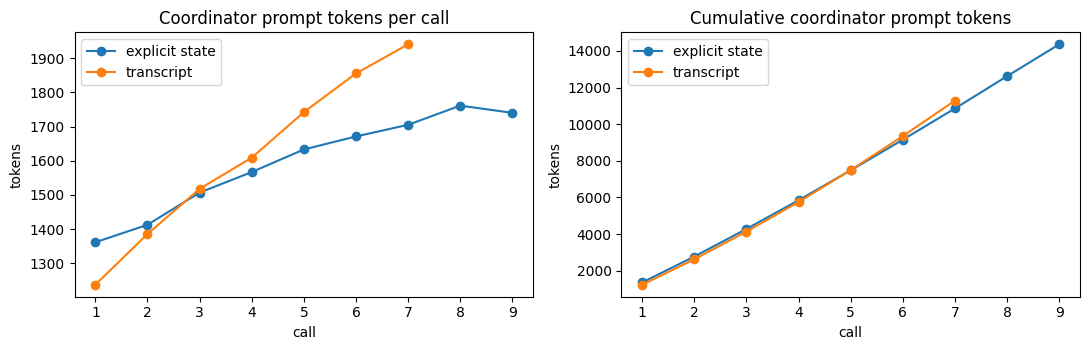

In [ ]:
import matplotlib.pyplot as plt

TRANSCRIPT_TEMPLATE = """Instructions:
{instructions}

You have no structured state. The history below is your only memory.

History:
{history}

Latest Observation: {observation}

Give your reasoning, then end with one line of the form `Action: <action>`."""


def run_transcript_coordinator(city: str, constraints: Dict, max_steps: int = 30) -> List[str]:
    env = CoordinatorEnv(city, constraints, paper_store, cached_agent_runner)
    model = llm.with_label(f"transcript:coordinator:{city}")
    obs, history, actions = env.reset(), [], []
    for _ in range(max_steps):
        hist = "\n\n".join(f"Observation: {o}\nResponse: {r}" for o, r in history) or "(none yet)"
        reply = model.complete(TRANSCRIPT_TEMPLATE.format(
            instructions=coordinator_instructions().text, history=hist, observation=obs)).text
        found = re.findall(r"Action:\s*`?([^`\n]+)`?", reply)
        action = found[-1].strip() if found else "wait"
        actions.append(action)
        history.append((obs, reply.strip()))
        obs, done = env.step(action)
        if done:
            break
    return actions


transcript_actions = run_transcript_coordinator("Seattle", CONSTRAINTS)


def coordinator_prompts(label: str) -> List[int]:
    return [u["prompt_tokens"] for u in USAGE if u["label"] == label]


state_tokens = coordinator_prompts("paper:coordinator:Seattle")
transcript_tokens = coordinator_prompts("transcript:coordinator:Seattle")
print(f"{'':28}{'steps':>7}{'first prompt':>14}{'last prompt':>13}{'cumulative':>12}")
for name, toks in (("explicit state (paper loop)", state_tokens), ("growing transcript", transcript_tokens)):
    print(f"{name:28}{len(toks):>7}{toks[0]:>14,}{toks[-1]:>13,}{sum(toks):>12,}")
print("\ntranscript actions:", transcript_actions)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for name, toks in (("explicit state", state_tokens), ("transcript", transcript_tokens)):
    a1.plot(range(1, len(toks) + 1), toks, marker="o", label=name)
    a2.plot(range(1, len(toks) + 1), np.cumsum(toks), marker="o", label=name)
a1.set(title="Coordinator prompt tokens per call", xlabel="call", ylabel="tokens")
a2.set(title="Cumulative coordinator prompt tokens", xlabel="call", ylabel="tokens")
a1.legend(); a2.legend(); plt.tight_layout(); plt.show()

## 3. The HarnessKernel

The paper's loop validates a state patch, merges it, and executes the action. It has
no point at which the harness can stop a step for reasons other than a malformed
patch: an agent calling the same failing tool again and again, a step budget running
out, an action the skill was never granted, an external submission nobody approved.
It also keeps everything in memory, so a process failure loses the run.

`HarnessKernel` runs the same per-step contract — the model still sees only *P*,
*Σ_t* and *O_t*, and its reasoning is still discarded — inside four control points:

| Control point | Hook | Checks here |
|---|---|---|
| Pre-inference gate | `on_pre_inference` | Step and token budgets |
| Streaming inspection | `on_stream_chunk` | Runaway or repetitive output, while it is generated |
| State commit boundary | `on_pre_commit` (after schema and invariants) | Domain rules on the merged state |
| Pre-action gate | `on_pre_action` | Permissions, repeated actions, approvals |

`on_post_inference` sees the full response before parsing. The order within one
step is: inference → parse → validate and check the merged state → pre-action gate →
**commit** (state plus a durable checkpoint) → execute the action → record that it
completed.

Middleware raises a typed `SemanticInterrupt`. A recovery policy maps each kind to
a decision — retry, redirect the model with the refusal, suspend, escalate to a
human, or fail — and the kernel moves through explicit states: `RUNNING`,
`INTERRUPTED`, `RECOVERING`, `SUSPENDED`, `COMPLETED`, `FAILED`. `TRANSITIONS` lists
the status changes that are allowed, and the kernel refuses any other. `FAILED` is
terminal; a suspended or completed execution is reopened through `RECOVERING`.

The streaming hook receives each new piece of output once. The stream guard keeps
running counts instead of re-reading the whole buffer, so checking a piece costs the
same at the end of a long response as at the start. Every model call produces its own
usage row, also when the kernel stops it early. Usage reported by the provider and
usage estimated from characters are labelled as such, because a stream closed early
never receives the provider's usage figures.

A malformed or invalid patch is retried inside the step with the error in the prompt,
which is the paper's rollback-retry. That error is all the model is shown of what went
wrong, so every invariant's message says how to fix the state, not only what is
wrong with it. If the patch is still invalid when the retries are spent, the
execution is escalated to a person, not failed: the committed state is intact, and
it can be resumed once someone has looked at the recording. When the harness refuses
an action and redirects the model, the new observation keeps the original one and
adds the refusal. Otherwise the model would lose what it was responding to, such as
the artifact id a dispatch just returned. An interrupt before the commit leaves *Σ*
unchanged. An interrupt from the action itself comes after the commit; the action
is then recorded as not completed.

**Recovering an action that never completed.** Re-running every unfinished action
on restart is only safe for some actions. Each action is therefore classified by
what it does, and recovery reads the class before it touches the action:

| Effect | Examples here | On restart |
|---|---|---|
| `read` | every data tool, `read_artifacts` | replay |
| `idempotent` | `dispatch_agent` (keyed by execution and task id), `request_approval` | replay; the key makes a repeat return the first result |
| `control` | `finish`, `wait`, `done` | replay |
| `external` | `submit_inquiry` | reconcile with the receiving system before anything is sent; escalate if it cannot be asked |
| `unknown` | anything not classified | escalate (`OUTCOME_UNKNOWN`): a person decides |

**Pins.** Every execution records what it runs under: the model, the skill version
and digest, the always-loaded artifacts, the state schema, and a digest of the exact
instructions it was given. Before a kernel runs anything, it compares all of them
with the current configuration and suspends with `PIN_MISMATCH` if any differ. This
notebook can only *verify* that the current configuration still matches. The skill
files on disk are its only copy, so it cannot run an older version. Notebook 2's
registry keeps every version and can *resolve* the exact configuration an execution
was pinned to.

In [ ]:
from collections import Counter


class Status(str, Enum):
    CREATED = "CREATED"
    RUNNING = "RUNNING"
    INTERRUPTED = "INTERRUPTED"
    RECOVERING = "RECOVERING"
    SUSPENDED = "SUSPENDED"
    COMPLETED = "COMPLETED"
    FAILED = "FAILED"


# The only status changes the kernel may make. FAILED is terminal; a SUSPENDED or COMPLETED
# execution is reopened through RECOVERING; RUNNING -> RECOVERING is a restart after a failure.
TRANSITIONS = {
    Status.CREATED: {Status.RUNNING},
    Status.RUNNING: {Status.INTERRUPTED, Status.SUSPENDED, Status.COMPLETED, Status.RECOVERING},
    Status.INTERRUPTED: {Status.RECOVERING, Status.SUSPENDED, Status.FAILED},
    Status.RECOVERING: {Status.RUNNING},
    Status.SUSPENDED: {Status.RECOVERING},
    Status.COMPLETED: {Status.RECOVERING},
    Status.FAILED: set(),
}


class Kind(str, Enum):
    LOOP_DETECTED = "LOOP_DETECTED"
    SCHEMA_VIOLATION = "SCHEMA_VIOLATION"
    POLICY_DENIED = "POLICY_DENIED"
    BUDGET_EXCEEDED = "BUDGET_EXCEEDED"
    STATE_CONFLICT = "STATE_CONFLICT"
    APPROVAL_REQUIRED = "APPROVAL_REQUIRED"
    STREAM_ABORTED = "STREAM_ABORTED"
    SOURCE_UNAVAILABLE = "SOURCE_UNAVAILABLE"
    OUTCOME_UNKNOWN = "OUTCOME_UNKNOWN"
    PIN_MISMATCH = "PIN_MISMATCH"


class SemanticInterrupt(Exception):
    """Raised by middleware, by an action, or by the kernel when execution must stop or change course."""

    def __init__(self, kind: Kind, message: str, hook: str, **detail):
        super().__init__(f"{kind.value}: {message}")
        self.kind, self.message, self.hook, self.detail = kind, message, hook, detail


class ProcessKilled(BaseException):
    """A simulated process failure. Not an interrupt: nothing in the kernel handles it."""


# --- what an action does, and what recovery may therefore do with it ------------------
class Effect(str, Enum):
    READ = "read"               # no side effects
    IDEMPOTENT = "idempotent"   # side effects the harness keys and deduplicates
    EXTERNAL = "external"       # reaches a system outside the harness
    CONTROL = "control"         # changes only this execution's own status
    UNKNOWN = "unknown"         # not classified: its outcome cannot be established


RECOVERY = {Effect.READ: "replay", Effect.IDEMPOTENT: "replay", Effect.CONTROL: "replay",
            Effect.EXTERNAL: "reconcile", Effect.UNKNOWN: "escalate"}


def _canonical(value):
    if isinstance(value, float) and value.is_integer():
        return int(value)
    if isinstance(value, str):
        return value.strip()
    if isinstance(value, dict):
        return {k.strip(): _canonical(v) for k, v in value.items()}
    if isinstance(value, list):
        return [_canonical(v) for v in value]
    return value


def action_name(action: str) -> str:
    call = parse_call(action)
    return call[0] if call else (action.split() or [""])[0]


def normalise_action(action: str) -> str:
    """One spelling per call: key order, whitespace and 850000 vs 850000.0 do not matter;
    any difference in a value does."""
    call = parse_call(action)
    if call:
        return f"call {call[0]} {json.dumps(_canonical(call[1]), sort_keys=True)}"
    return " ".join(action.split())


def digest_text(text: str) -> str:
    return hashlib.sha256((text or "").encode()).hexdigest()[:12]


class Middleware:
    """Synchronous hooks. Each receives the kernel, which exposes the current state, the
    step number, the harness's record of completed actions, and the store."""

    def on_pre_inference(self, k): ...
    def on_stream_start(self, k): ...
    def on_stream_chunk(self, k, piece: str): ...
    def on_post_inference(self, k, text: str): ...
    def on_pre_commit(self, k, candidate: Dict, patch: Dict): ...
    def on_pre_action(self, k, action: str): ...


class BudgetMiddleware(Middleware):
    def __init__(self, max_steps: int, max_prompt_tokens: Optional[int] = None):
        self.max_steps, self.max_prompt_tokens = max_steps, max_prompt_tokens

    def on_pre_inference(self, k):
        if k.step_no >= self.max_steps:
            raise SemanticInterrupt(Kind.BUDGET_EXCEEDED, f"{k.step_no} of {self.max_steps} steps used",
                                    "pre_inference")
        if self.max_prompt_tokens and k.prompt_tokens_used >= self.max_prompt_tokens:
            raise SemanticInterrupt(Kind.BUDGET_EXCEEDED,
                                    f"{k.prompt_tokens_used} of {self.max_prompt_tokens} prompt tokens used",
                                    "pre_inference")


class StreamGuardMiddleware(Middleware):
    """Stops a generation that runs away or repeats itself, while it is being produced.
    It looks at each new piece once and keeps running counts, so the cost per piece does
    not grow with the length of the output."""

    def __init__(self, max_chars: int = 8000, max_repeats: int = 8, min_line: int = 40):
        self.max_chars, self.max_repeats, self.min_line = max_chars, max_repeats, min_line

    def on_stream_start(self, k):
        self.chars, self.partial, self.lines = 0, "", Counter()

    def on_stream_chunk(self, k, piece: str):
        self.chars += len(piece)
        if self.chars > self.max_chars:
            raise SemanticInterrupt(Kind.STREAM_ABORTED, f"output exceeded {self.max_chars} characters", "stream")
        *complete, self.partial = (self.partial + piece).split("\n")
        for line in (l.strip() for l in complete):
            if len(line) > self.min_line:
                self.lines[line] += 1
                if self.lines[line] >= self.max_repeats:
                    raise SemanticInterrupt(Kind.STREAM_ABORTED,
                                            f"a line repeated {self.max_repeats} times in the output", "stream")


class PermissionMiddleware(Middleware):
    def __init__(self, granted: set):
        self.granted = set(granted)

    def on_pre_action(self, k, action: str):
        name = action_name(action)
        if name not in self.granted:
            raise SemanticInterrupt(Kind.POLICY_DENIED, f"'{name}' is not granted to {k.role}",
                                    "pre_action", action=action)


class LoopDetectorMiddleware(Middleware):
    """Repetition of one call (after normalisation), judged by what the earlier attempts returned:

    - it failed every time before: refused at the `fail_limit`-th attempt (a retry loop);
    - it returned the same result every time before: refused at the `stall_limit`-th attempt
      (no new information);
    - it returned different results: allowed, as polling a changing status is, up to `poll_limit`.

    The history is the completed actions in the store. An action left unfinished by a process
    failure has no completion, so its replay on resume is counted once, when it completes."""

    def __init__(self, fail_limit: int = 3, stall_limit: int = 3, poll_limit: int = 10):
        self.fail_limit, self.stall_limit, self.poll_limit = fail_limit, stall_limit, poll_limit

    def on_pre_action(self, k, action: str):
        norm = normalise_action(action)
        prior = [h for h in k.history if h["norm"] == norm]
        if not prior:
            return
        n = len(prior) + 1
        failed = [h for h in prior if h["observation"].startswith("ERROR")]
        if len(failed) == len(prior) and n >= self.fail_limit:
            raise SemanticInterrupt(
                Kind.LOOP_DETECTED, f"'{action[:80]}' failed {len(prior)} times before", "pre_action",
                action=action, pattern="repeated_failure",
                source_unavailable=prior[-1]["observation"].startswith("ERROR (source unavailable)"))
        if not failed and len({h["digest"] for h in prior}) == 1 and n >= self.stall_limit:
            raise SemanticInterrupt(Kind.LOOP_DETECTED,
                                    f"'{action[:80]}' returned the same result {len(prior)} times",
                                    "pre_action", action=action, pattern="no_new_information")
        if n > self.poll_limit:
            raise SemanticInterrupt(Kind.LOOP_DETECTED, f"'{action[:80]}' attempted {n} times",
                                    "pre_action", action=action, pattern="poll_limit")


class FinishCheckMiddleware(Middleware):
    """An agent may only finish with a complete draft of the artifact kind its skill promises."""

    def __init__(self, agent: str):
        self.agent = agent

    def on_pre_action(self, k, action: str):
        if action.strip() != "finish":
            return
        d = k.candidate.get("draft") or {}
        if d.get("kind") != OUTPUT_KIND[self.agent] or not d.get("summary") or d.get("content") in (None, {}, []):
            raise SemanticInterrupt(Kind.STATE_CONFLICT,
                                    f"finish needs a draft with kind '{OUTPUT_KIND[self.agent]}', a summary "
                                    "and content", "pre_action")


class ApprovalGateMiddleware(Middleware):
    """External submissions need a person's approval of exactly the payload that would be
    sent, recorded in the store. The state's own fields are not evidence: the model writes
    the state. `payload_for(state, kind)` says what would be sent."""

    GATED = {"submit_inquiry"}

    def __init__(self, payload_for: Callable[[Dict, str], Dict]):
        self.payload_for = payload_for

    def on_pre_action(self, k, action: str):
        parts = action.split()
        if parts and parts[0] in self.GATED:
            kind = parts[1] if len(parts) > 1 else ""
            payload = self.payload_for(k.candidate, kind)
            ok, reason = k.store.check_approval(k.execution_id, f"{parts[0]} {kind}", payload,
                                                now=getattr(k, "now", time.time)())
            if not ok:
                raise SemanticInterrupt(Kind.POLICY_DENIED, reason, "pre_action", action=action)


# What the kernel does with each kind of interrupt.
DEFAULT_POLICY = {
    Kind.SCHEMA_VIOLATION: "escalate",              # only raised once the in-step retries are spent
    Kind.STATE_CONFLICT: "redirect_or_escalate",    # escalate when the in-step retries are spent
    Kind.POLICY_DENIED: "redirect",
    Kind.LOOP_DETECTED: "suspend_or_redirect",   # suspend if the source is down, else redirect
    Kind.BUDGET_EXCEEDED: "suspend",
    Kind.APPROVAL_REQUIRED: "escalate",
    Kind.STREAM_ABORTED: "retry",
    Kind.SOURCE_UNAVAILABLE: "suspend",
    Kind.OUTCOME_UNKNOWN: "escalate",
    Kind.PIN_MISMATCH: "escalate",
}
MAX_REDIRECTS, MAX_RETRIES = 2, 1


class Faults:
    """Simulated process failures for the demonstrations. ProcessKilled is not handled by
    the kernel: the Python objects are lost, and only what reached SQLite survives."""

    def __init__(self, kill_after_commits: Optional[int] = None, kill_after_send: bool = False):
        self.kill_after_commits, self.kill_after_send, self.commits = kill_after_commits, kill_after_send, 0

    def after_commit(self, k):
        self.commits += 1
        if self.kill_after_commits and self.commits == self.kill_after_commits:
            raise ProcessKilled(f"process killed after commit {self.commits} ({k.role}, step {k.step_no})")

    def after_send(self):
        if self.kill_after_send:
            self.kill_after_send = False
            raise ProcessKilled("process killed after the request was sent, before its result was recorded")

In [ ]:
class Store:
    """Durable harness records in one SQLite file. Checkpoints, events and completions are
    only ever inserted. Logically separate tables share one persistence layer."""

    DDL = """
    CREATE TABLE IF NOT EXISTS branches (name TEXT PRIMARY KEY, parent TEXT, from_checkpoint TEXT,
        assumptions TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS executions (id TEXT PRIMARY KEY, branch TEXT, role TEXT,
        parent_execution TEXT, task_id TEXT, status TEXT, config TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS checkpoints (id TEXT PRIMARY KEY, execution_id TEXT, branch TEXT,
        parent_id TEXT, step INTEGER, state TEXT, schema_digest TEXT, config TEXT, action TEXT,
        event TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS completions (checkpoint_id TEXT PRIMARY KEY, execution_id TEXT,
        action TEXT, observation TEXT, outcome TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS artifacts (id TEXT PRIMARY KEY, kind TEXT, branch TEXT, summary TEXT,
        content TEXT, inputs TEXT, produced_by TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS events (seq INTEGER PRIMARY KEY AUTOINCREMENT, execution_id TEXT,
        branch TEXT, role TEXT, kind TEXT, detail TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS journal (key TEXT PRIMARY KEY, execution_id TEXT, action TEXT,
        payload TEXT, status TEXT, result TEXT, created REAL, updated REAL);
    CREATE TABLE IF NOT EXISTS approvals (id TEXT PRIMARY KEY, execution_id TEXT, branch TEXT,
        action TEXT, payload TEXT, payload_digest TEXT, status TEXT, decided_by TEXT, created REAL,
        decided REAL, expires REAL);
    """

    def __init__(self, path: Path):
        self.path = Path(path)
        self.db = sqlite3.connect(self.path, check_same_thread=False)
        self.db.row_factory = sqlite3.Row
        self.db.executescript(self.DDL)
        self._seq: Counter = Counter()

    # -- helpers ------------------------------------------------------------------
    def _x(self, sql, *args):
        cur = self.db.execute(sql, args)
        self.db.commit()
        return cur

    def _one(self, sql, *args) -> Optional[Dict]:
        row = self.db.execute(sql, args).fetchone()
        return dict(row) if row else None

    def df(self, table: str) -> pd.DataFrame:
        return pd.read_sql_query(f"SELECT * FROM {table}", self.db)

    def _id(self, prefix: str) -> str:
        """Sequential ids. A run that repeats the same steps gets the same ids, which is
        what lets a recorded run be replayed: ids appear in what the model reads."""
        self._seq[prefix] += 1
        return f"{prefix}_{self._seq[prefix]:05d}"

    # -- branches and executions ----------------------------------------------------
    def add_branch(self, name, parent=None, from_checkpoint=None, assumptions=None):
        self._x("INSERT OR IGNORE INTO branches VALUES (?,?,?,?,?)", name, parent, from_checkpoint,
                json.dumps(assumptions or {}), time.time())

    def lineage(self, branch: str) -> List[str]:
        out = []
        while branch:
            out.append(branch)
            row = self._one("SELECT parent FROM branches WHERE name=?", branch)
            branch = row["parent"] if row else None
        return out

    def new_execution(self, branch, role, config, parent_execution=None, task_id=None) -> str:
        eid = self._id("ex")
        self._x("INSERT INTO executions VALUES (?,?,?,?,?,?,?,?)", eid, branch, role, parent_execution,
                task_id, Status.CREATED.value, json.dumps(config), time.time())
        return eid

    def execution(self, eid) -> Dict:
        row = self._one("SELECT * FROM executions WHERE id=?", eid)
        row["config"] = json.loads(row["config"])
        return row

    def executions(self, **where) -> List[Dict]:
        sql = "SELECT * FROM executions" + (" WHERE " + " AND ".join(f"{k}=?" for k in where) if where else "")
        rows = [dict(r) for r in self.db.execute(sql + " ORDER BY created", tuple(where.values()))]
        for r in rows:
            r["config"] = json.loads(r["config"])
        return rows

    def set_status(self, eid, status: Status):
        self._x("UPDATE executions SET status=? WHERE id=?", status.value, eid)

    # -- checkpoints and completions ------------------------------------------------
    def add_checkpoint(self, eid, branch, state, step, config, schema_digest, action, event,
                       parent_id=None) -> str:
        cid = self._id("cp")
        self._x("INSERT INTO checkpoints VALUES (?,?,?,?,?,?,?,?,?,?,?)", cid, eid, branch, parent_id, step,
                json.dumps(state), schema_digest, json.dumps(config), action, event, time.time())
        return cid

    def _cp(self, row) -> Optional[Dict]:
        if row:
            row["state"], row["config"] = json.loads(row["state"]), json.loads(row["config"])
        return row

    def checkpoint(self, cid) -> Dict:
        return self._cp(self._one("SELECT * FROM checkpoints WHERE id=?", cid))

    def latest_checkpoint(self, eid) -> Dict:
        return self._cp(self._one("SELECT * FROM checkpoints WHERE execution_id=? "
                                  "ORDER BY step DESC, created DESC LIMIT 1", eid))

    def complete(self, cid, eid, action, observation, outcome):
        self._x("INSERT OR IGNORE INTO completions VALUES (?,?,?,?,?,?)", cid, eid, action, observation,
                outcome, time.time())

    def completion(self, cid) -> Optional[Dict]:
        return self._one("SELECT * FROM completions WHERE checkpoint_id=?", cid)

    def completed_actions(self, eid) -> List[Dict[str, str]]:
        """The harness's memory of what this execution did. Never shown to the model."""
        rows = self.db.execute("SELECT action, observation FROM completions WHERE execution_id=? "
                               "ORDER BY created", (eid,)).fetchall()
        return [history_entry(r["action"], r["observation"]) for r in rows]

    # -- artifacts --------------------------------------------------------------------
    def put_artifact(self, kind, branch, summary, content, inputs, produced_by) -> str:
        aid = artifact_id(kind, content, inputs)
        self._x("INSERT OR IGNORE INTO artifacts VALUES (?,?,?,?,?,?,?,?)", aid, kind, branch, summary,
                json.dumps(content, default=str), json.dumps(inputs), json.dumps(produced_by), time.time())
        return aid

    def artifact(self, aid) -> Optional[Dict]:
        row = self._one("SELECT * FROM artifacts WHERE id=?", aid)
        if row:
            for k in ("content", "inputs", "produced_by"):
                row[k] = json.loads(row[k])
        return row

    def artifact_of_execution(self, eid) -> Optional[Dict]:
        row = self._one("SELECT id FROM artifacts WHERE json_extract(produced_by, '$.execution')=?", eid)
        return self.artifact(row["id"]) if row else None

    def visible(self, branch, aid) -> bool:
        a = self._one("SELECT branch FROM artifacts WHERE id=?", aid)
        return bool(a) and a["branch"] in self.lineage(branch)

    def read_artifacts(self, branch, ids) -> Dict[str, Any]:
        return {i: {k: a[k] for k in ("kind", "summary", "content")}
                for i in ids if self.visible(branch, i) and (a := self.artifact(i))}

    def latest_of_kinds(self, branch, ids, kinds) -> Dict[str, Dict]:
        found = {}
        for aid in ids:
            a = self.artifact(aid) if self.visible(branch, aid) else None
            if a and a["kind"] in kinds and (a["kind"] not in found or a["created"] > found[a["kind"]]["created"]):
                found[a["kind"]] = a
        return {k: {"id": a["id"], "summary": a["summary"], "content": a["content"]} for k, a in found.items()}

    # -- events, journal, approvals --------------------------------------------------
    def event(self, eid, branch, role, event_kind, **detail):
        self._x("INSERT INTO events (execution_id, branch, role, kind, detail, created) VALUES (?,?,?,?,?,?)",
                eid, branch, role, event_kind, json.dumps(detail, default=str), time.time())

    def journal_get(self, key) -> Optional[Dict]:
        row = self._one("SELECT * FROM journal WHERE key=?", key)
        if row:
            row["payload"] = json.loads(row["payload"])
            row["result"] = json.loads(row["result"]) if row["result"] else None
        return row

    def journal_intent(self, key, eid, action, payload):
        self._x("INSERT INTO journal VALUES (?,?,?,?,?,?,?,?)", key, eid, action, json.dumps(payload),
                "intent", None, time.time(), time.time())

    def journal_done(self, key, result):
        self._x("UPDATE journal SET status='done', result=?, updated=? WHERE key=?", json.dumps(result),
                time.time(), key)

    def request_approval(self, eid, branch, action, payload) -> str:
        """A request for a person to approve one exact payload. A pending request for a
        different payload of the same action is superseded."""
        digest = payload_digest(payload)
        pending = self.db.execute("SELECT id, payload_digest FROM approvals WHERE execution_id=? AND action=? "
                                  "AND status='pending'", (eid, action)).fetchall()
        for r in pending:
            if r["payload_digest"] == digest:
                return r["id"]
            self._x("UPDATE approvals SET status='superseded' WHERE id=?", r["id"])
        aid = self._id("ap")
        self._x("INSERT INTO approvals VALUES (?,?,?,?,?,?,?,?,?,?,?)", aid, eid, branch, action,
                json.dumps(payload, sort_keys=True), digest, "pending", None, time.time(), None, None)
        return aid

    def approve(self, approval_id, decided_by: str, valid_for_s: float = 24 * 3600):
        now = time.time()
        self._x("UPDATE approvals SET status='approved', decided_by=?, decided=?, expires=? WHERE id=? "
                "AND status='pending'", decided_by, now, now + valid_for_s, approval_id)

    def approval(self, approval_id) -> Optional[Dict]:
        row = self._one("SELECT * FROM approvals WHERE id=?", approval_id)
        if row:
            row["payload"] = json.loads(row["payload"])
        return row

    def check_approval(self, eid, action, payload, now=None) -> Tuple[bool, str]:
        """Is there an approval by a person, for this execution, this action and exactly this
        payload, that has not expired? Returns (ok, reason)."""
        now = time.time() if now is None else now
        rows = [dict(r) for r in self.db.execute(
            "SELECT * FROM approvals WHERE execution_id=? AND action=? AND status='approved' "
            "ORDER BY decided DESC", (eid, action))]
        if not rows:
            return False, f"no recorded approval for '{action}' in this execution"
        digest = payload_digest(payload)
        match = [r for r in rows if r["payload_digest"] == digest]
        if not match:
            return False, (f"the approved payload ({rows[0]['payload_digest']}) differs from the one "
                           f"about to be sent ({digest})")
        live = [r for r in match if r["expires"] and r["expires"] > now]
        if not live:
            return False, f"the approval {match[0]['id']} expired"
        return True, f"approved by {live[0]['decided_by']} ({live[0]['id']}, payload {digest})"

    def valid_approval(self, eid, action, payload, now=None) -> Optional[Dict]:
        ok, _ = self.check_approval(eid, action, payload, now)
        if not ok:
            return None
        return self._one("SELECT * FROM approvals WHERE execution_id=? AND action=? AND status='approved' "
                         "AND payload_digest=? ORDER BY decided DESC LIMIT 1", eid, action, payload_digest(payload))

    def pending_approvals(self) -> List[Dict]:
        return [dict(r) for r in self.db.execute("SELECT * FROM approvals WHERE status='pending'")]


def payload_digest(payload: Dict) -> str:
    return hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:16]


def history_entry(action: str, observation: str) -> Dict[str, str]:
    return {"action": action, "norm": normalise_action(action), "observation": (observation or "")[:300],
            "digest": digest_text(observation)}

In [ ]:
def schema_digest(schema: Dict) -> str:
    return hashlib.sha256(json.dumps(schema, sort_keys=True).encode()).hexdigest()[:12]


def pin_config(skill_name: str, schema: Dict, instructions: str) -> Dict[str, Any]:
    """What an execution is pinned to: the model, the skill version and digest, the always-loaded
    artifacts, the state schema, and the exact instructions compiled from them."""
    a = ARTIFACTS[skill_name]
    return {"model": MODEL, "skill": {"name": a.name, "version": a.version, "digest": a.digest},
            "always": {x.name: x.digest for x in ALWAYS}, "schema_digest": schema_digest(schema),
            "instructions_digest": digest_text(instructions)}


def pin_mismatches(pinned: Dict, current: Dict) -> List[Dict[str, Any]]:
    """Every pinned field whose current value differs."""
    out = []
    for key in ("model", "schema_digest", "instructions_digest"):
        if pinned.get(key) != current.get(key):
            out.append({"pin": key, "pinned": pinned.get(key), "current": current.get(key)})
    if pinned["skill"] != current["skill"]:
        out.append({"pin": "skill", "pinned": pinned["skill"], "current": current["skill"]})
    for name in sorted(set(pinned["always"]) | set(current["always"])):
        if pinned["always"].get(name) != current["always"].get(name):
            out.append({"pin": f"always:{name}", "pinned": pinned["always"].get(name),
                        "current": current["always"].get(name)})
    return out


def start_execution(store: Store, branch: str, role: str, skill_name: str, initial_state: Dict,
                    schema: Dict, instructions: str, parent_execution=None, task_id=None,
                    from_checkpoint=None) -> str:
    config = pin_config(skill_name, schema, instructions)
    eid = store.new_execution(branch, role, config, parent_execution, task_id)
    store.add_checkpoint(eid, branch, initial_state, step=0, config=config,
                         schema_digest=config["schema_digest"], action=None,
                         event="fork" if from_checkpoint else "start", parent_id=from_checkpoint)
    return eid


class HarnessKernel:
    """Runs one execution: the SKILL.state step contract inside the harness's control points.

    The model sees only the instructions P, the current state and the latest observation.
    Each validated state is committed as a checkpoint before its action runs; each action that
    finishes is recorded as completed. A new kernel built from the same store and execution id
    resumes from the latest checkpoint. An action that was committed but never completed is
    recovered according to its effect: replayed, reconciled, or handed to a person."""

    def __init__(self, store: Store, execution_id: str, *, role: str, skill_name: str, instructions: str,
                 schema: Dict, checks: List[Callable], llm, middleware: List[Middleware],
                 act: Callable, effect_of: Callable[[str], Effect],
                 reconcile: Optional[Callable] = None, policy: Optional[Dict] = None,
                 max_retries: int = 2, faults: Optional[Faults] = None):
        self.store, self.execution_id, self.role, self.skill_name = store, execution_id, role, skill_name
        self.instructions, self.schema, self.checks, self.llm = instructions, schema, checks, llm
        self.middleware, self.act, self.effect_of, self.reconcile = middleware, act, effect_of, reconcile
        self.policy, self.max_retries, self.faults = policy or DEFAULT_POLICY, max_retries, faults
        ex = store.execution(execution_id)
        self.branch, self.config = ex["branch"], ex["config"]
        cp = store.latest_checkpoint(execution_id)
        self.state, self.step_no, self.last_checkpoint = cp["state"], cp["step"], cp["id"]
        self.candidate: Dict = {}
        self.history = store.completed_actions(execution_id)        # harness memory, never prompted
        self._unfinished = (cp["action"], cp["id"]) if cp["action"] and not store.completion(cp["id"]) else None
        self.prompt_tokens_used, self.redirects, self.retries = 0, 0, Counter()
        self.calls: List[int] = []                                   # this kernel's rows in USAGE
        self.last_interrupt: Optional[SemanticInterrupt] = None
        self.status = Status(ex["status"])
        if self.status is not Status.CREATED:
            self.event("resumed", previous_status=self.status.value, from_checkpoint=cp["id"],
                       unfinished_action=self._unfinished[0] if self._unfinished else None)
            self.set_status(Status.RECOVERING)

    # -- records -------------------------------------------------------------------
    def event(self, name: str, **detail):
        self.store.event(self.execution_id, self.branch, self.role, name,
                         skill=self.config["skill"], **detail)

    def set_status(self, status: Status, **detail) -> Status:
        if status is self.status:
            return status
        if status not in TRANSITIONS[self.status]:
            raise RuntimeError(f"illegal status change {self.status.value} -> {status.value}")
        self.event("status", frm=self.status.value, to=status.value, **detail)
        self.status = status
        self.store.set_status(self.execution_id, status)
        return status

    def current_pins(self) -> Dict[str, Any]:
        return {**pin_config(self.skill_name, self.schema, self.instructions), "model": self.llm.model}

    def pin_mismatches(self) -> List[Dict[str, Any]]:
        return pin_mismatches(self.config, self.current_pins())

    # -- the run loop ----------------------------------------------------------------
    def run(self, observation: str = "", max_steps: int = 40) -> Status:
        self.set_status(Status.RUNNING)
        obs = observation
        for i in range(max_steps):
            try:
                if i == 0:
                    self._check_pins()          # before anything runs under this configuration
                obs, outcome = self._advance(obs)
            except SemanticInterrupt as si:
                decision = self._handle(si)
                if decision == "redirect":         # keep what the model was shown, add the refusal
                    obs = (f"{obs}\n\nYour last response was refused ({si.kind.value}): {si.message}. "
                           "The state is unchanged. Respond again to the observation above.")
                    continue
                if decision == "retry":
                    continue
                return self.status
            if outcome == "done":
                return self.set_status(Status.COMPLETED)
            if outcome == "wait":
                return self.set_status(Status.SUSPENDED, reason="waiting for input")
        self._handle(SemanticInterrupt(Kind.BUDGET_EXCEEDED, f"{max_steps} steps in one run", "run"))
        return self.status

    def _check_pins(self):
        diff = self.pin_mismatches()
        if diff:
            raise SemanticInterrupt(Kind.PIN_MISMATCH, "configuration differs from the pinned one: "
                                    + ", ".join(d["pin"] for d in diff), "pre_inference", mismatches=diff)

    def _advance(self, obs: str):
        if self._unfinished:                        # committed before a failure, never completed
            action, cid = self._unfinished
            effect = self.effect_of(action)
            plan = RECOVERY[effect] if effect is not Effect.EXTERNAL or self.reconcile else "escalate"
            self.event("recovery_plan", action=action, checkpoint=cid, effect=effect.value, plan=plan)
            if plan == "escalate":
                raise SemanticInterrupt(Kind.OUTCOME_UNKNOWN,
                                        f"'{action[:80]}' ({effect.value}) may or may not have taken effect",
                                        "recovery", action=action, checkpoint=cid)
            self._unfinished = None
            if plan == "reconcile":
                return self._execute(action, cid, handler=self.reconcile)
            return self._execute(action, cid)
        return self.step(obs)

    def step(self, observation: str):
        for m in self.middleware:
            m.on_pre_inference(self)
        retry_error, retry_kind = None, Kind.SCHEMA_VIOLATION
        for _ in range(self.max_retries + 1):
            prompt = build_prompt(self.instructions, self.state, observation, retry_error)
            text = self._generate(prompt)
            for m in self.middleware:
                m.on_post_inference(self, text)
            try:
                parsed = parse_response(text)
                candidate = merge(self.state, parsed.state_patch)
                errors = validate(candidate, self.schema)
                if errors:
                    raise SemanticInterrupt(Kind.SCHEMA_VIOLATION, "; ".join(errors[:4]), "pre_commit")
                errors = [e for c in self.checks for e in c(candidate)]
                if errors:
                    raise SemanticInterrupt(Kind.STATE_CONFLICT, "; ".join(errors[:4]), "pre_commit")
                for m in self.middleware:
                    m.on_pre_commit(self, candidate, parsed.state_patch)
            except ParseError as e:
                retry_error, retry_kind = f"unparseable response: {e}", Kind.SCHEMA_VIOLATION
                self.event("rejected_patch", kind=Kind.SCHEMA_VIOLATION.value, error=retry_error)
                continue
            except SemanticInterrupt as si:
                if si.kind not in (Kind.SCHEMA_VIOLATION, Kind.STATE_CONFLICT):
                    raise
                retry_error, retry_kind = si.message, si.kind   # the paper's rollback-retry: state unchanged
                self.event("rejected_patch", kind=si.kind.value, error=si.message)
                continue
            break
        else:
            raise SemanticInterrupt(retry_kind,
                                    f"no valid state patch in {self.max_retries + 1} attempts: {retry_error}",
                                    "pre_commit", exhausted=True)
        action = parsed.action
        self.candidate = candidate
        for m in self.middleware:
            m.on_pre_action(self, action)
        # --- commit boundary: the state becomes durable before the action runs ---------
        self.state, self.step_no = candidate, self.step_no + 1
        cid = self.store.add_checkpoint(self.execution_id, self.branch, self.state, self.step_no, self.config,
                                        self.config["schema_digest"], action, "commit", self.last_checkpoint)
        self.last_checkpoint = cid
        if self.faults:
            self.faults.after_commit(self)
        return self._execute(action, cid)

    def _execute(self, action: str, cid: str, handler: Optional[Callable] = None):
        obs, outcome = (handler or self.act)(action, self)   # may raise; then not completed
        self.store.complete(cid, self.execution_id, action, obs, outcome)
        self.history.append(history_entry(action, obs))
        return obs, outcome

    def _generate(self, prompt: str) -> str:
        gen, pieces = self.llm.start(prompt), []
        gen.record["execution_id"] = self.execution_id
        for m in self.middleware:
            m.on_stream_start(self)
        try:
            for piece in gen:
                pieces.append(piece)
                for m in self.middleware:
                    m.on_stream_chunk(self, piece)
        finally:
            gen.close()                             # stops the generation if it is still running
            self.calls.append(gen.record["call"])
            self.prompt_tokens_used += gen.record["prompt_tokens"]
        return "".join(pieces)

    def _handle(self, si: SemanticInterrupt) -> str:
        self.last_interrupt = si
        self.event("interrupt", kind=si.kind.value, hook=si.hook, message=si.message,
                   **{k: v for k, v in si.detail.items() if k != "kind"})
        self.set_status(Status.INTERRUPTED, kind=si.kind.value)
        rule = self.policy.get(si.kind, "fail")
        if rule == "suspend_or_redirect":
            rule = "suspend" if si.detail.get("source_unavailable") else "redirect"
        if rule == "redirect_or_escalate":
            rule = "escalate" if si.detail.get("exhausted") else "redirect"
        if rule == "redirect" and self.redirects >= MAX_REDIRECTS:
            rule = "escalate"                       # redirects spent: a person looks at it
        if rule == "retry" and self.retries[si.kind] >= MAX_RETRIES:
            rule = "fail"
        self.event("recovery", kind=si.kind.value, decision=rule)
        if rule in ("redirect", "retry"):
            if rule == "redirect":
                self.redirects += 1
            else:
                self.retries[si.kind] += 1
            self.set_status(Status.RECOVERING)
            self.set_status(Status.RUNNING)
            return rule
        if rule in ("suspend", "escalate"):
            self.set_status(Status.SUSPENDED, reason=si.kind.value, needs_human=rule == "escalate")
        else:
            self.set_status(Status.FAILED, reason=si.kind.value)
        return "stop"

### 3.1 Agents and the coordinator under the kernel

Both levels now run as kernel executions in one SQLite store. A dispatch creates a
child execution for the agent with its own checkpoints, linked to the coordinator's
execution. When the agent finishes, its artifact is stored with its inputs and with
the provenance of the instructions it ran under: the skill version and digest, the
surface digest, and the section ids that were compiled in. Notebook 3 uses that
provenance to trace a failure back to skill sections.

What each execution may do is granted, not taken from the skill: the tools and
actions its skill requests, intersected with what this harness implements. The
parent skill requests `create_branch`, but branching is something the buyer does
through the harness, so that request is not granted. A dispatch on a branch that has
no city yet is refused with an error the model sees.

The agent's middleware stack is a 14-step budget, the stream guard, permissions, the
loop detector and the finish check. The coordinator's is a 40-step budget, the
stream guard, permissions, the loop detector and the approval gate.

An unavailable data source is handled by the harness, not left to the model. The
first failed call returns the error to the agent, which may try another route. The
second one raises `SOURCE_UNAVAILABLE` from the action, and the policy suspends the
agent with its last call recorded as not completed. The coordinator's dispatch then
raises the same interrupt, so the branch suspends too.

`dispatch_agent` is idempotent per coordinator execution and task id. When a
dispatch runs again, `run_agent` looks for an earlier agent execution for that task.
If one finished, its artifact is returned without a new run. If one is suspended or
was cut off by a failure, it resumes from its own checkpoint. Only if none exists, or
it failed, does a new execution start. So the coordinator can always replay an
unfinished dispatch.

`MortgageInquiryEndpoint` stands in for a lender's API in section 6. It records
requests instead of sending them anywhere. Like many real APIs, it accepts an
idempotency key and can be asked whether a request with that key has arrived. That
lookup is what makes `submit_inquiry` reconcilable.

In [ ]:
IMPLEMENTED_VERBS = {"dispatch_agent", "request_approval", "submit_inquiry"}
CONTROL_VERBS = {"wait", "done"}


class MortgageInquiryEndpoint:
    """Stands in for a lender's API: records each request it receives, sends nothing anywhere."""

    def __init__(self):
        self.received: List[Dict] = []

    def submit(self, key: str, payload: Dict) -> Dict:
        receipt = {"confirmation": "MQ-" + key[:8].upper(), "received_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
        self.received.append({"idempotency_key": key, "payload": payload, **receipt})
        return receipt

    def lookup(self, key: str) -> Optional[Dict]:
        hit = [r for r in self.received if r["idempotency_key"] == key]
        return {"confirmation": hit[0]["confirmation"], "received_at": hit[0]["received_at"]} if hit else None


# What each action does. Recovery reads this before it touches an unfinished action;
# anything not listed is UNKNOWN and goes to a person.
TOOL_EFFECTS = {"query_sales": Effect.READ, "metro_value_series": Effect.READ, "market_heat": Effect.READ,
                "value_forecast": Effect.READ, "run_regression": Effect.READ, "hazard_profile": Effect.READ,
                "insurance_scenarios": Effect.READ, "affordability": Effect.READ, "read_artifacts": Effect.READ}
COORD_EFFECTS = {"dispatch_agent": Effect.IDEMPOTENT,     # keyed by (coordinator execution, task id)
                 "request_approval": Effect.IDEMPOTENT,   # a pending request for one payload is reused
                 "submit_inquiry": Effect.EXTERNAL,
                 "wait": Effect.CONTROL, "done": Effect.CONTROL}


def agent_effect(action: str) -> Effect:
    if action.strip() == "finish":
        return Effect.CONTROL
    call = parse_call(action)
    return TOOL_EFFECTS.get(call[0], Effect.UNKNOWN) if call else Effect.UNKNOWN


def coordinator_effect(action: str) -> Effect:
    return COORD_EFFECTS.get(action_name(action), Effect.UNKNOWN)


def inquiry_payload(state: Dict, kind: str) -> Dict[str, Any]:
    """Exactly what `submit_inquiry <kind>` would send from this state. The approval binds to it."""
    return {"action": f"submit_inquiry {kind}", "city": state["branch"]["city"],
            "scenario": state["branch"].get("scenario"), "constraints": state["constraints"],
            "summary": (state.get("pending_action") or {}).get("summary", "")}


UNAVAILABLE_LIMIT = 2      # failed calls to unavailable sources before the harness suspends the agent


def agent_kernel(store: Store, eid: str, agent: str, instructions: str, granted: List[str]) -> HarnessKernel:
    branch = store.execution(eid)["branch"]
    used: Dict[str, Any] = {"tools": set(), "ids": set(), "unavailable": 0}

    def act(action: str, k: HarnessKernel):
        if action.strip() == "finish":
            return "Finished.", "done"
        call = parse_call(action)
        if call is None:
            return f"ERROR: unrecognised action '{action}'. Use `call <tool> <JSON>` or `finish`.", None
        name, args = call
        try:
            result = run_tool(name, args, lambda ids: store.read_artifacts(branch, ids))
        except ToolUnavailable as e:
            used["unavailable"] += 1
            k.event("source_unavailable", tool=name, args=args, error=str(e), count=used["unavailable"])
            if used["unavailable"] >= UNAVAILABLE_LIMIT:
                raise SemanticInterrupt(Kind.SOURCE_UNAVAILABLE,
                                        f"{used['unavailable']} calls to unavailable sources, last: {name}",
                                        "action", tool=name, args=args)
            return f"ERROR (source unavailable): {e}", None
        except Exception as e:
            return f"ERROR: {type(e).__name__}: {e}", None
        used["tools"].add(name)
        if name == "read_artifacts":
            used["ids"].update(args.get("ids", []))
        return compact(result), None

    k = HarnessKernel(store, eid, role=agent, skill_name=AGENT_SKILL[agent], instructions=instructions,
                      schema=AGENT_SCHEMA, checks=agent_checks(agent),
                      llm=llm.with_label(f"kernel:{agent}:{branch}"),
                      middleware=[BudgetMiddleware(14), StreamGuardMiddleware(),
                                  PermissionMiddleware(set(granted) | {"finish"}),
                                  LoopDetectorMiddleware(), FinishCheckMiddleware(agent)],
                      act=act, effect_of=agent_effect)
    k.used = used
    return k


def run_agent(store: Store, coord: HarnessKernel, agent: str, task_id: str) -> Dict:
    s, branch = coord.state, coord.branch
    city, constraints = s["branch"]["city"], s["constraints"]
    refs = list(s.get("artifacts", {}))
    upstream = store.latest_of_kinds(branch, refs, UPSTREAM_KINDS.get(agent, []))
    extra = {}
    if agent == "synthesis":
        extra["artifacts in this branch"] = compact({i: v.get("kind") for i, v in s.get("artifacts", {}).items()})
    granted = granted_tools(AGENT_SKILL[agent], IMPLEMENTED_TOOLS)
    surface = agent_instructions(agent, city, constraints, upstream, granted, extra)
    # Dispatch is idempotent per (coordinator execution, task id): a finished child is reused,
    # an unfinished one is resumed from its checkpoint, a failed one is replaced.
    children = store.executions(parent_execution=coord.execution_id, task_id=task_id, role=agent)
    live = [e for e in children if e["status"] != Status.FAILED.value]
    if live and live[-1]["status"] == Status.COMPLETED.value:
        a = store.artifact_of_execution(live[-1]["id"])
        if a:
            coord.event("dispatch_reconciled", task=task_id, execution=live[-1]["id"], artifact=a["id"])
            return {"status": "done", "artifact_id": a["id"], "kind": a["kind"], "summary": a["summary"],
                    "gaps": {}, "execution": live[-1]["id"]}
    if live and live[-1]["status"] != Status.COMPLETED.value:
        eid = live[-1]["id"]
        observation = f"Task {task_id} resumes after an interruption. Continue."
    else:
        eid = start_execution(store, branch, agent, AGENT_SKILL[agent], initial_agent_state(), AGENT_SCHEMA,
                              surface.text, parent_execution=coord.execution_id, task_id=task_id)
        observation = f"Task {task_id}: {agent} for {city}. Begin."
    k = agent_kernel(store, eid, agent, surface.text, granted)
    status = k.run(observation, max_steps=16)
    draft, gaps = k.state.get("draft") or {}, k.state.get("gaps") or {}
    if status is Status.COMPLETED:
        ids = {u["id"] for u in upstream.values()} | k.used["ids"]
        aid = store.put_artifact(
            draft["kind"], branch, draft.get("summary", ""), draft.get("content"),
            artifact_inputs(agent, city, constraints, k.used["tools"], ids),
            {"agent": agent, "execution": eid, "skill": k.config["skill"],
             "surface_digest": surface.manifest["surface_digest"],
             "sections": [f"{x['artifact']}:{x['section']}" for x in surface.manifest["sections"]]})
        return {"status": "done", "artifact_id": aid, "kind": draft["kind"],
                "summary": draft.get("summary", ""), "gaps": gaps, "execution": eid}
    si = k.last_interrupt
    if status is Status.SUSPENDED and si and (si.kind is Kind.SOURCE_UNAVAILABLE or
                                              si.detail.get("source_unavailable")):
        return {"status": "suspended", "reason": si.message, "gaps": gaps, "execution": eid}
    return {"status": "failed", "reason": si.message if si else f"ended {status.value} without an artifact",
            "gaps": gaps, "execution": eid}


def submit_with_journal(store: Store, endpoint, k: HarnessKernel, kind: str,
                        faults: Optional[Faults]) -> str:
    """Send at most once. Also the reconciliation path: run again after a failure, it finds the
    journal entry and asks the endpoint before sending anything."""
    action, payload = f"submit_inquiry {kind}", inquiry_payload(k.state, kind)
    approval = store.valid_approval(k.execution_id, action, payload)
    if approval is None:                           # re-checked here, not only at the gate
        raise SemanticInterrupt(Kind.POLICY_DENIED, store.check_approval(k.execution_id, action, payload)[1],
                                "action", action=action)
    digest = payload_digest(payload)
    key = hashlib.sha256(f"{k.execution_id}|{action}|{approval['id']}|{digest}".encode()).hexdigest()[:16]
    entry = store.journal_get(key)
    if entry and entry["status"] == "done":
        return f"Already submitted: confirmation {entry['result']['confirmation']} (key {key})."
    if entry is None:
        store.journal_intent(key, k.execution_id, action, payload)
    already = endpoint.lookup(key) if entry else None     # did it arrive before we lost track?
    receipt = already or endpoint.submit(key, {**payload, "payload_digest": digest, "approval": approval["id"]})
    if faults:
        faults.after_send()
    store.journal_done(key, receipt)
    k.event("external_action", action=action, key=key, payload_digest=digest, approval=approval["id"],
            reconciled=bool(already), confirmation=receipt["confirmation"])
    note = " It had already been received; it was not sent again." if already else ""
    return f"Submitted {kind}: confirmation {receipt['confirmation']} (key {key}).{note}"


def coordinator_kernel(store: Store, eid: str, endpoint, faults: Optional[Faults] = None) -> HarnessKernel:
    def act(action: str, k: HarnessKernel):
        parts = action.split()
        verb = parts[0] if parts else ""
        kind = parts[1] if len(parts) > 1 else ""
        if verb == "done":
            return "Branch finished.", "done"
        if verb == "wait":
            return "Waiting for the buyer.", "wait"
        if verb == "dispatch_agent":
            if len(parts) != 3 or parts[1] not in AGENT_SKILL:
                return "ERROR: use `dispatch_agent <agent> <task_id>` with a known agent.", None
            if not k.state["branch"].get("city"):
                return "ERROR: this branch has no city yet. `wait` for the buyer.", None
            r = run_agent(store, k, parts[1], parts[2])
            if r["status"] == "suspended":
                raise SemanticInterrupt(Kind.SOURCE_UNAVAILABLE, describe_result(parts[1], parts[2], r),
                                        "action", agent=parts[1], task=parts[2])
            return describe_result(parts[1], parts[2], r), None
        if verb == "request_approval":
            payload = inquiry_payload(k.state, kind)
            ok, reason = store.check_approval(k.execution_id, f"submit_inquiry {kind}", payload)
            if ok:
                return f"The buyer's approval is recorded: {reason}.", None
            aid = store.request_approval(k.execution_id, k.branch, f"submit_inquiry {kind}", payload)
            raise SemanticInterrupt(Kind.APPROVAL_REQUIRED, f"{kind} needs the buyer's approval", "action",
                                    approval=aid, payload_digest=payload_digest(payload))
        if verb == "submit_inquiry":
            return submit_with_journal(store, endpoint, k, kind, faults), None
        return f"ERROR: unknown action '{action}'.", None

    def reconcile(action: str, k: HarnessKernel):
        if action_name(action) == "submit_inquiry" and hasattr(endpoint, "lookup"):
            return act(action, k)                  # the journalled path checks before it sends
        raise SemanticInterrupt(Kind.OUTCOME_UNKNOWN, f"cannot establish whether '{action}' took effect",
                                "recovery", action=action)

    granted = set(granted_tools(COORD_SKILL, IMPLEMENTED_VERBS)) | CONTROL_VERBS
    return HarnessKernel(store, eid, role="coordinator", skill_name=COORD_SKILL,
                         instructions=coordinator_instructions().text, schema=COORD_SCHEMA,
                         checks=COORD_CHECKS, llm=llm.with_label(f"kernel:coordinator:{store.execution(eid)['branch']}"),
                         middleware=[BudgetMiddleware(40), StreamGuardMiddleware(), PermissionMiddleware(granted),
                                     LoopDetectorMiddleware(), ApprovalGateMiddleware(inquiry_payload)],
                         act=act, effect_of=coordinator_effect,
                         reconcile=reconcile if hasattr(endpoint, "lookup") else None, faults=faults)


STORE = Store(WORK / "harness.db")
ENDPOINT = MortgageInquiryEndpoint()
print("store:", STORE.path)
print("coordinator may use:", sorted(set(granted_tools(COORD_SKILL, IMPLEMENTED_VERBS)) | CONTROL_VERBS))
print("coordinator's skill requests:", ARTIFACTS[COORD_SKILL].requires["tools"])

store: /content/ch04_work/harness.db
coordinator may use: ['dispatch_agent', 'done', 'request_approval', 'submit_inquiry', 'wait']
coordinator's skill requests: ['dispatch_agent', 'create_branch', 'request_approval', 'submit_inquiry']


### 3.2 The kernel on one agent

Before running whole branches, one agent on its own. The insurance data service is
down for Kent, so `SERVICE_DOWN` holds `"Kent"`. Because the King County aggregate is
built from the regional feeds, it is unavailable too while any region is down. The
insurance agent for Kent runs under the kernel with no upstream artifacts. The cell
prints how the run ended and every event the kernel recorded for it.

In [ ]:
from types import SimpleNamespace


def events(execution_id: Optional[str] = None, branch: Optional[str] = None,
           kinds: Optional[List[str]] = None) -> pd.DataFrame:
    df = STORE.df("events")
    if execution_id:
        df = df[df.execution_id == execution_id]
    if branch:
        df = df[df.branch == branch]
    if kinds:
        df = df[df.kind.isin(kinds)]
    df = df.copy()
    df["detail"] = df.detail.map(lambda d: {k: v for k, v in json.loads(d).items() if k != "skill"})
    return df[["seq", "branch", "role", "kind", "detail"]]


def show_events(df: pd.DataFrame, width: int = 110) -> None:
    for r in df.itertuples():
        print(f"  {r.seq:>4} {r.role:18}{r.kind:19}{compact(r.detail, width)}")


def ending(k: HarnessKernel) -> str:
    si = k.last_interrupt
    return f"{k.status.value}" + (f" after {si.kind.value}: {si.message[:160]}" if si else "")


def resumable(eid: str) -> bool:
    """FAILED is terminal. Say what ended an execution instead of trying to reopen it."""
    ex = STORE.execution(eid)
    if ex["status"] != Status.FAILED.value:
        return True
    print(f"{ex['branch']} ({ex['role']}) is FAILED, which is terminal; it is not resumed. What ended it:")
    show_events(events(eid, kinds=["rejected_patch", "interrupt", "recovery"]))
    return False


SERVICE_DOWN.clear()
SERVICE_DOWN.add("Kent")
STORE.add_branch("demo")
demo_granted = granted_tools("insurance-finance", IMPLEMENTED_TOOLS)
demo_surface = agent_instructions("insurance_finance", "Kent", CONSTRAINTS, {}, demo_granted)
demo_eid = start_execution(STORE, "demo", "insurance_finance", "insurance-finance", initial_agent_state(),
                           AGENT_SCHEMA, demo_surface.text, task_id="demo")
demo = agent_kernel(STORE, demo_eid, "insurance_finance", demo_surface.text, demo_granted)
demo_status = demo.run("Task demo: insurance_finance for Kent. Begin.", max_steps=16)
SERVICE_DOWN.clear()

print(f"granted: {demo_granted}")
print(f"status: {demo_status.value}   steps committed: {demo.step_no}   "
      f"last interrupt: {demo.last_interrupt.kind.value if demo.last_interrupt else None}")
last = STORE.latest_checkpoint(demo_eid)
print(f"latest checkpoint: step {last['step']}, action {last['action']!r}, "
      f"completed: {STORE.completion(last['id']) is not None}\n")
show_events(events(demo_eid))

granted: ['affordability', 'insurance_scenarios']
status: SUSPENDED   steps committed: 2   last interrupt: SOURCE_UNAVAILABLE
latest checkpoint: step 2, action 'call insurance_scenarios {"region":"King County"}', completed: False

     1 insurance_finance status             {"frm":"CREATED","to":"RUNNING"}
     2 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"Kent"},"error":"insurance data service: request for 'Kent' tim...(truncated)
     3 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"King County"},"error":"insurance data service: request for 'Ki...(truncated)
     4 insurance_finance interrupt          {"kind":"SOURCE_UNAVAILABLE","hook":"action","message":"2 calls to unavailable sources, last: insurance_scenar...(truncated)
     5 insurance_finance status             {"frm":"RUNNING","to":"INTERRUPTED","kind":"SOURCE_UNAVAILABLE"}
     6 insurance_finance recovery           {"kind":"SOURCE_UNAVAILABLE","de

### 3.3 Pins are checked before anything runs

The agent above is suspended. Resuming it with the instructions it was pinned to
would pass the pin check. Resuming it with instructions that differ by one added
fact must not run at all, because the execution would then continue under
instructions it did not start with. The first line compares the pins without
building a kernel. The second resumes with the changed instructions; the pin check
runs before the unfinished action is recovered and before any model call.

In [ ]:
pinned = STORE.execution(demo_eid)["config"]
same = {**pin_config("insurance-finance", AGENT_SCHEMA, demo_surface.text), "model": llm.model}
print("with the pinned instructions:", pin_mismatches(pinned, same) or "every pin holds")

changed = agent_instructions("insurance_finance", "Kent", CONSTRAINTS, {}, demo_granted,
                             {"note": "a fact added after the run started"})
calls_before = len(USAGE)
k = agent_kernel(STORE, demo_eid, "insurance_finance", changed.text, demo_granted)
st = k.run("Continue.")
print(f"with changed instructions: {st.value}, {k.last_interrupt.kind.value}, "
      f"model calls made: {len(USAGE) - calls_before}")
for d in k.last_interrupt.detail["mismatches"]:
    print(f"  {d['pin']:22}pinned {d['pinned']}   current {d['current']}")

with the pinned instructions: every pin holds
with changed instructions: SUSPENDED, PIN_MISMATCH, model calls made: 0
  instructions_digest   pinned 22215e83e6e3   current 3e673313a126


### 3.4 Pre-action gates and the loop detector, without a model

The next cell passes candidate actions through the agent's pre-action middleware
directly and prints what each gate decides. No model is called. The second table
checks the loop detector against the cases that matter in practice. Three identical
calls are not always a loop: a call that keeps failing is, and so is one that keeps
returning the same result. A call whose result changes each time, such as polling a
status, is making progress and is allowed up to a limit. Key order, whitespace and
`850000` vs `850000.0` do not make two calls different; a different value does.
Section 4 checks the remaining case, an action left unfinished by a process failure,
on the real run's history.

In [ ]:
def gate_decision(middleware: List[Middleware], probe, action: str) -> str:
    try:
        for m in middleware:
            m.on_pre_action(probe, action)
        return "allowed"
    except SemanticInterrupt as si:
        return f"{si.kind.value}: {si.message}"


def probe_agent(history=(), draft=None):
    return SimpleNamespace(role="insurance_finance", history=list(history),
                           candidate={**initial_agent_state(), **({"draft": draft} if draft else {})})


gates = [PermissionMiddleware(set(demo_granted) | {"finish"}), LoopDetectorMiddleware(),
         FinishCheckMiddleware("insurance_finance")]
complete = {"kind": "affordability", "summary": "s", "content": {"x": 1}}
for situation, probe, action in [
        ("fresh agent", probe_agent(), 'call insurance_scenarios {"region": "Kent"}'),
        ("fresh agent", probe_agent(), 'call hazard_profile {"city": "Kent"}'),
        ("fresh agent", probe_agent(), "finish"),
        ("with a complete draft", probe_agent(draft=complete), "finish"),
        ("with the wrong kind", probe_agent(draft={**complete, "kind": "report"}), "finish")]:
    print(f"{situation:24}{action[:46]:48}{gate_decision(gates, probe, action)}")

kent = 'call insurance_scenarios {"region": "Kent"}'
county = 'call insurance_scenarios {"region": "King County"}'
pay = 'call affordability {"price_usd": 700000, "down_payment_pct": 20, "annual_insurance_usd": 2400}'
pay_float = 'call affordability {"annual_insurance_usd": 2400.0, "price_usd": 700000.0, "down_payment_pct": 20}'
err = "ERROR (source unavailable): HTTP 503"
H = history_entry
loop_cases = [
    ("failed once before", [H(kent, err)], kent),
    ("failed twice before, same arguments", [H(kent, err)] * 2, kent),
    ("failed twice before, other spelling", [H(kent, err)] * 2, ' call insurance_scenarios { "region" : "Kent" } '),
    ("failed twice before, other value", [H(kent, err)] * 2, county),
    ("same result twice before", [H(pay, '{"monthly_total_usd":4200}')] * 2, pay),
    ("same result twice, 700000.0 vs 700000", [H(pay, '{"monthly_total_usd":4200}')] * 2, pay_float),
    ("three different results before", [H(kent, f'{{"status":"step {i}"}}') for i in range(3)], kent),
    ("ten different results before", [H(kent, f'{{"status":"step {i}"}}') for i in range(10)], kent),
]
print(f"\n{'loop detector':40}{'attempt':>8}  decision")
for situation, history, action in loop_cases:
    print(f"{situation:40}{len(history) + 1:>8}  {gate_decision([LoopDetectorMiddleware()], probe_agent(history), action)}")

fresh agent             call insurance_scenarios {"region": "Kent"}     allowed
fresh agent             call hazard_profile {"city": "Kent"}            POLICY_DENIED: 'hazard_profile' is not granted to insurance_finance
fresh agent             finish                                          STATE_CONFLICT: finish needs a draft with kind 'affordability', a summary and content
with a complete draft   finish                                          allowed
with the wrong kind     finish                                          STATE_CONFLICT: finish needs a draft with kind 'affordability', a summary and content

loop detector                            attempt  decision
failed once before                             2  allowed
failed twice before, same arguments            3  LOOP_DETECTED: 'call insurance_scenarios {"region": "Kent"}' failed 2 times before
failed twice before, other spelling            3  LOOP_DETECTED: ' call insurance_scenarios { "region" : "Kent" } ' failed 2 times be

### 3.5 A loop, interrupted in a live run

The probes above call the loop detector directly. Here it acts during a real run. The
market-heat service answers every request with `HTTP 429 Too Many Requests. Retry the
request.` (`RATE_LIMITED` holds `market_heat`). That is not an outage, so the
unavailable-source rule does not apply. The market-research agent for Bellevue runs
under the kernel, and whatever it does with the refusals is up to the model.

If it retries the identical call, the third attempt is refused before it runs:
`LOOP_DETECTED`, pattern `repeated_failure`. The policy redirects: the execution goes
`RUNNING → INTERRUPTED → RECOVERING → RUNNING`, and the model is shown the last
observation with the refusal added. It can then continue without market heat and
record the gap. If it keeps looping after the redirects are spent, the execution is
escalated: `INTERRUPTED → SUSPENDED`. The cell prints which of these happened, the
status changes, and what the model did after the refusal.

In [ ]:
RATE_LIMITED.add("market_heat")
loop_granted = granted_tools("market-research", IMPLEMENTED_TOOLS)
loop_surface = agent_instructions("market_research", "Bellevue", CONSTRAINTS, {}, loop_granted)
loop_eid = start_execution(STORE, "demo", "market_research", "market-research", initial_agent_state(),
                           AGENT_SCHEMA, loop_surface.text, task_id="loop-demo")
lk = agent_kernel(STORE, loop_eid, "market_research", loop_surface.text, loop_granted)
try:
    loop_status = lk.run("Task loop-demo: market_research for Bellevue. Begin.", max_steps=16)
finally:
    RATE_LIMITED.clear()

ev = events(loop_eid)
loops = ev[(ev.kind == "interrupt") & ev.detail.map(lambda d: d.get("kind") == "LOOP_DETECTED")]
print(f"ended: {ending(lk)}")
print(f"loop interrupts: {len(loops)}")
for r in loops.itertuples():
    print(f"   {r.detail['pattern']}: {r.detail['message']}")
st = [r.detail for r in ev[ev.kind == "status"].itertuples()]
print("status path:", " > ".join([st[0]["frm"]] + [d["to"] for d in st]))

print("\nactions in order (the refused one never ran, so it has no completion):")
for h in STORE.completed_actions(loop_eid):
    print(f"   {h['action'][:60]:62}{textwrap.shorten(h['observation'], 60)}")
print("gaps recorded by the agent:", lk.state.get("gaps") or "none")

ended: COMPLETED after LOOP_DETECTED: 'call market_heat {"months":24}' failed 2 times before
loop interrupts: 1
   repeated_failure: 'call market_heat {"months":24}' failed 2 times before
status path: CREATED > RUNNING > INTERRUPTED > RECOVERING > RUNNING > COMPLETED

actions in order (the refused one never ran, so it has no completion):
   call metro_value_series {}                                    {"region":"Seattle metro","as_of":"2026-09- [...]
   call market_heat {"months":24}                                ERROR: RateLimited: market_heat: HTTP 429 Too Many [...]
   call market_heat {"months":24}                                ERROR: RateLimited: market_heat: HTTP 429 Too Many [...]
   call query_sales {"city":"Bellevue","budget_usd":850000}      [...]
   finish                                                        Finished.
gaps recorded by the agent: {'market_heat': 'The Seattle-metro market heat index could not be retrieved because the tool returned HTTP 429 rate-limit error

### 3.6 Recovery reads the action's effect

`effect_of` classifies every action an execution can commit. The cell prints the
class and recovery plan for each kind of action in this notebook, then exercises the
case that must not be replayed blindly. It writes a coordinator checkpoint directly
into the store whose `submit_inquiry` was committed and never completed, as if the
process had died during the send. It then resumes it against a lender endpoint that
accepts requests but cannot be asked whether one arrived. The harness cannot know
whether the inquiry went out, so it neither sends it again nor assumes it was sent.

In [ ]:
for action, effect_of in [('call hazard_profile {"city": "Kent"}', agent_effect), ("finish", agent_effect),
                          ("dispatch_agent market_research t1", coordinator_effect),
                          ("request_approval mortgage_inquiry", coordinator_effect),
                          ("submit_inquiry mortgage_inquiry", coordinator_effect),
                          ("transfer_deposit 50000", coordinator_effect)]:
    e = effect_of(action)
    print(f"{action:42}{e.value:12}{RECOVERY[e]}")


class FireAndForgetEndpoint:
    """Accepts requests; offers no way to ask whether one arrived."""

    def __init__(self):
        self.received = []

    def submit(self, key, payload):
        self.received.append(key)
        return {"confirmation": "FF-" + key[:8]}


ff_state = merge(initial_coord_state(), {
    "phase": "approval", "constraints": CONSTRAINTS, "branch": {"city": "Kent", "scenario": "baseline"},
    "pending_action": {"kind": "mortgage_inquiry", "summary": "inquiry", "approved": True}})
ff_eid = start_execution(STORE, "demo", "coordinator", COORD_SKILL, initial_coord_state(), COORD_SCHEMA,
                         coordinator_instructions().text)
ex = STORE.execution(ff_eid)
STORE.add_checkpoint(ff_eid, "demo", ff_state, 1, ex["config"], ex["config"]["schema_digest"],
                     "submit_inquiry mortgage_inquiry", "commit",
                     STORE.latest_checkpoint(ff_eid)["id"])
STORE.set_status(ff_eid, Status.RUNNING)                      # the process died while running

ff = FireAndForgetEndpoint()
calls_before = len(USAGE)
k = coordinator_kernel(STORE, ff_eid, ff)
st = k.run("Continue.")
print(f"\n{st.value}, {k.last_interrupt.kind.value}: {k.last_interrupt.message}")
print(f"requests sent: {len(ff.received)}   model calls made: {len(USAGE) - calls_before}")
show_events(events(ff_eid, kinds=["resumed", "recovery_plan", "recovery"]))

call hazard_profile {"city": "Kent"}      read        replay
finish                                    control     replay
dispatch_agent market_research t1         idempotent  replay
request_approval mortgage_inquiry         idempotent  replay
submit_inquiry mortgage_inquiry           external    reconcile
transfer_deposit 50000                    unknown     escalate

SUSPENDED, OUTCOME_UNKNOWN: 'submit_inquiry mortgage_inquiry' (external) may or may not have taken effect
requests sent: 0   model calls made: 0
    22 coordinator       resumed            {"previous_status":"RUNNING","from_checkpoint":"cp_00011","unfinished_action":"submit_inquiry mortgage_inquiry...(truncated)
    25 coordinator       recovery_plan      {"action":"submit_inquiry mortgage_inquiry","checkpoint":"cp_00011","effect":"external","plan":"escalate"}
    28 coordinator       recovery           {"kind":"OUTCOME_UNKNOWN","decision":"escalate"}


## 4. Durable checkpoints and a resume

Every committed state is now a row in SQLite, written before its action runs, and
every action that finishes writes a completion row. A process failure loses the
Python objects but not those rows. A new kernel built from the same execution id loads
the latest checkpoint. If that checkpoint's action has no completion, the kernel
recovers it according to its effect, as in section 3.5, before it asks the model for
anything.

The investigation starts on a `shared` branch. The coordinator records the buyer's
constraints and then waits, because the buyer has not yet chosen cities. Its latest
checkpoint, `C0`, is the shared starting point every city branch forks from.

A fork copies a checkpoint's state, applies the branch's assumptions as a patch,
validates the result against the schema and the invariants, and starts a new
execution whose first checkpoint points back to the one it came from.

Seattle runs first, with a fault injected: the process is killed right after the
coordinator's fourth commit, before that commit's action runs.

In [ ]:
STORE.add_branch("shared")
root_eid = start_execution(STORE, "shared", "coordinator", COORD_SKILL, initial_coord_state(), COORD_SCHEMA,
                           coordinator_instructions().text)
root = coordinator_kernel(STORE, root_eid, ENDPOINT)
root_status = root.run(f"Buyer constraints: {json.dumps(CONSTRAINTS)}. The buyer has not chosen which "
                       "cities to compare yet. Record the constraints, then `wait` for the buyer.", max_steps=6)
C0 = root.last_checkpoint
c0_state = STORE.checkpoint(C0)["state"]
print(f"root: {root_status.value} after {root.step_no} steps;  C0 = {C0}")
print("phase:", c0_state["phase"])
print("recorded constraints:", c0_state["constraints"])
print("match the buyer's:", c0_state["constraints"] == CONSTRAINTS)


def fork(store: Store, from_checkpoint: str, branch: str, patch: Dict) -> str:
    """A new branch from a committed checkpoint: copy, patch, validate, start an execution."""
    cp = store.checkpoint(from_checkpoint)
    state = merge(cp["state"], patch)
    errors = validate(state, COORD_SCHEMA) + [e for c in COORD_CHECKS for e in c(state)]
    if errors:
        raise ValueError(f"fork '{branch}' would start from an invalid state: {errors}")
    store.add_branch(branch, parent=cp["branch"], from_checkpoint=from_checkpoint, assumptions=patch)
    return start_execution(store, branch, "coordinator", COORD_SKILL, state, COORD_SCHEMA,
                           coordinator_instructions().text, from_checkpoint=from_checkpoint)


def brief(city: str) -> str:
    return (f"This branch researches {city} under the recorded constraints. Dispatch the agents, record "
            "their artifacts, run synthesis last, then `done`.")


city_eids: Dict[str, str] = {}

root: SUSPENDED after 1 steps;  C0 = cp_00013
phase: constraints
recorded constraints: {'budget_usd': 850000, 'down_payment_pct': 20, 'horizon_years': 10, 'risk_tolerance': 'medium', 'financing': '30-year fixed'}
match the buyer's: True


In [ ]:
KILL_AFTER = 4
city_eids["Seattle"] = fork(STORE, C0, "seattle",
                            {"branch": {"city": "Seattle", "scenario": "baseline"}, "phase": "research"})
k = coordinator_kernel(STORE, city_eids["Seattle"], ENDPOINT, Faults(kill_after_commits=KILL_AFTER))
try:
    k.run(brief("Seattle"), max_steps=40)
    print(f"Seattle ended {ending(k)} before commit {KILL_AFTER}; no failure was injected.")
except ProcessKilled as e:
    print("ProcessKilled:", e)
del k                                       # the in-memory kernel is gone
crash_time = time.time()

ex = STORE.execution(city_eids["Seattle"])
cp = STORE.latest_checkpoint(city_eids["Seattle"])
print(f"\nin SQLite: status {ex['status']}, latest checkpoint step {cp['step']}, action {cp['action']!r}, "
      f"completed: {STORE.completion(cp['id']) is not None}")
before = STORE.executions(parent_execution=city_eids["Seattle"])
for e in before:
    print(f"  agent execution {e['id']}  task {e['task_id']:6}{e['role']:24}{e['status']}")

ProcessKilled: process killed after commit 4 (coordinator, step 4)

in SQLite: status RUNNING, latest checkpoint step 4, action 'dispatch_agent insurance_finance seattle_insurance', completed: False
  agent execution ex_00006  task seattle_marketmarket_research         COMPLETED
  agent execution ex_00007  task seattle_quantitativequantitative_analysis   COMPLETED
  agent execution ex_00008  task seattle_environmentalenvironmental_risk      COMPLETED


In [ ]:
if resumable(city_eids["Seattle"]):
    k = coordinator_kernel(STORE, city_eids["Seattle"], ENDPOINT)       # a new process, same store
    seattle_status = k.run("The harness restarted after a failure. Continue from your state.", max_steps=40)
    print(f"Seattle: {ending(k)}, at step {k.step_no}")
    show_events(events(city_eids["Seattle"], kinds=["resumed", "recovery_plan"]))

    agents_after = STORE.executions(parent_execution=city_eids["Seattle"])
    done_before = {e["task_id"] for e in before if e["status"] == Status.COMPLETED.value}
    rerun = sorted({e["task_id"] for e in agents_after if e["created"] > crash_time} & done_before)
    print(f"\nagent executions completed before the failure: {len(done_before)}")
    print(f"  of those, run again after the resume: {len(rerun)} {rerun or ''}")
    print(f"agent executions after the resume: {sum(e['created'] > crash_time for e in agents_after)}")

    seattle_final = k.state
    print(f"\nphase: {seattle_final['phase']}")
    for t, v in seattle_final["tasks"].items():
        print(f"  task {t:10}{v['agent']:24}{v['status']:9}{', '.join(v.get('artifacts', []))}")
    report = STORE.latest_of_kinds("seattle", list(seattle_final["artifacts"]), ["report"]).get("report")
    print("\nreport:", report["summary"] if report else "none")

Seattle: COMPLETED, at step 6
    40 coordinator       resumed            {"previous_status":"RUNNING","from_checkpoint":"cp_00033","unfinished_action":"dispatch_agent insurance_financ...(truncated)
    43 coordinator       recovery_plan      {"action":"dispatch_agent insurance_finance seattle_insurance","checkpoint":"cp_00033","effect":"idempotent","...(truncated)

agent executions completed before the failure: 3
  of those, run again after the resume: 0 
agent executions after the resume: 2

phase: synthesis
  task seattle_marketmarket_research         done     a_9c679e07c0
  task seattle_quantitativequantitative_analysis   done     a_dae40883b8
  task seattle_environmentalenvironmental_risk      done     a_b19d05fde4
  task seattle_insuranceinsurance_finance       done     a_0c6e51d9da
  task seattle_synthesissynthesis               failed   

report: none


### 4.1 Checking the history, not the final status

A run that ends `COMPLETED` can still have done something wrong on the way: run an
agent twice, skip a status, leave an action without a completion in the middle of
its history. `audit_execution` reads an execution's records from SQLite and checks
them:

- the checkpoints form one chain, step 0 to *n*, each pointing to the one before;
- only the latest checkpoint may have an action without a completion;
- every status change is in `TRANSITIONS`, each starts where the previous one ended,
  and the stored status is the last one;
- no task was completed by two agent executions;
- every action recovered after a failure completed once and appears once in the
  history the loop detector reads;
- every journalled external action is marked done and reached the endpoint once.

It is used after every failure scenario from here on.

In [ ]:
def audit_execution(store: Store, eid: str, endpoint=None) -> pd.DataFrame:
    ex = store.execution(eid)
    cps = store.df("checkpoints").query("execution_id == @eid").sort_values(["step", "created"])
    comps = store.df("completions").query("execution_id == @eid")
    ev = events(eid)
    ids, parents = list(cps.id), list(cps.parent_id)
    acted = cps[cps.action.notna()]
    completed = set(comps.checkpoint_id)
    unfinished = [c for c in acted.id if c not in completed]
    rows = [
        ("checkpoints run 0..n, each pointing to the previous one",
         list(cps.step) == list(range(len(cps))) and all(parents[i] == ids[i - 1] for i in range(1, len(ids))),
         f"{len(cps)} checkpoints"),
        ("only the latest checkpoint may lack a completion", all(c == ids[-1] for c in unfinished),
         f"{len(unfinished)} without a completion"),
    ]
    st = [r.detail for r in ev[ev.kind == "status"].itertuples()]
    rows.append(("status changes legal, chained, and match the stored status",
                 all(Status(d["to"]) in TRANSITIONS[Status(d["frm"])] for d in st)
                 and all(st[i]["frm"] == st[i - 1]["to"] for i in range(1, len(st)))
                 and (not st or st[-1]["to"] == ex["status"]),
                 " > ".join([st[0]["frm"]] + [d["to"] for d in st]) if st else ex["status"]))
    children = store.executions(parent_execution=eid)
    if children:
        per_task = Counter(c["task_id"] for c in children if c["status"] == Status.COMPLETED.value)
        rows.append(("no task completed by two agent executions", all(n == 1 for n in per_task.values()),
                     f"{len(children)} agent executions, {len(per_task)} tasks completed"))
    history = store.completed_actions(eid)
    for r in ev[ev.kind == "recovery_plan"].itertuples():
        a = r.detail["action"]
        n_done = int((comps.checkpoint_id == r.detail["checkpoint"]).sum())
        n_hist = sum(h["norm"] == normalise_action(a) for h in history)
        rows.append((f"recovered action ran once: {a[:35]}",
                     n_done <= 1 and n_hist <= 1, f"plan {r.detail['plan']}, completions {n_done}, in history {n_hist}"))
    journal = store.df("journal").query("execution_id == @eid")
    for j in journal.itertuples():
        sent = sum(x["idempotency_key"] == j.key for x in endpoint.received) if endpoint else None
        rows.append((f"external '{j.action}' done and received once", j.status == "done" and sent in (None, 1),
                     f"journal {j.status}, received {sent}"))
    return pd.DataFrame(rows, columns=["check", "ok", "detail"])


def show_audit(store: Store, eid: str, endpoint=None) -> bool:
    a = audit_execution(store, eid, endpoint)
    ex = store.execution(eid)
    print(f"audit of {ex['role']} on {ex['branch']} ({eid}):")
    for r in a.itertuples():
        print(f"  {'ok  ' if r.ok else 'FAIL'}  {r.check[:62]:64}{r.detail}")
    return bool(a.ok.all())


show_audit(STORE, city_eids["Seattle"])

audit of coordinator on seattle (ex_00005):
  ok    checkpoints run 0..n, each pointing to the previous one         7 checkpoints
  ok    only the latest checkpoint may lack a completion                0 without a completion
  ok    status changes legal, chained, and match the stored status      CREATED > RUNNING > RECOVERING > RUNNING > COMPLETED
  ok    no task completed by two agent executions                       5 agent executions, 4 tasks completed
  ok    recovered action ran once: dispatch_agent insurance_finance se  plan replay, completions 1, in history 1


True

## 5. Branches: a suspended city and a changed assumption

Bellevue and Kent fork from the same `C0`. Each branch sees its own artifacts and
those of its ancestors, never a sibling's: `Store.visible` walks the branch's lineage.

Kent runs while the insurance data service is down for Kent. If the insurance agent
hits the outage twice, it suspends, the dispatch raises `SOURCE_UNAVAILABLE`, and the
Kent branch suspends with that dispatch not completed. Bellevue does not use Kent's
insurance data. The first cell prints how each branch ended.

The second cell ends the outage. If Kent is suspended, its coordinator resumes,
re-runs the dispatch, and the insurance agent resumes from its own checkpoint. The
cell prints the resume events of both and which branches can see which artifacts.

In [ ]:
SERVICE_DOWN.clear()
SERVICE_DOWN.add("Kent")
for city in ("Bellevue", "Kent"):
    city_eids[city] = fork(STORE, C0, city.lower(),
                           {"branch": {"city": city, "scenario": "baseline"}, "phase": "research"})
    k = coordinator_kernel(STORE, city_eids[city], ENDPOINT)
    st = k.run(brief(city), max_steps=40)
    si = k.last_interrupt
    print(f"{city:9}{st.value:11}step {k.step_no:<4}"
          f"last interrupt: {si.kind.value + ' - ' + si.message[:70] if si else None}")

print("\nKent's agent executions:")
for e in STORE.executions(parent_execution=city_eids["Kent"]):
    print(f"  {e['id']}  task {e['task_id']:6}{e['role']:24}{e['status']}")

Bellevue COMPLETED  step 7   last interrupt: None
Kent     SUSPENDED  step 4   last interrupt: SOURCE_UNAVAILABLE - Task kent_insurance_finance (insurance_finance) suspended: 2 calls to 

Kent's agent executions:
  ex_00019  task kent_market_researchmarket_research         COMPLETED
  ex_00020  task kent_quantitative_analysisquantitative_analysis   COMPLETED
  ex_00021  task kent_environmental_riskenvironmental_risk      COMPLETED
  ex_00022  task kent_insurance_financeinsurance_finance       SUSPENDED


In [ ]:
SERVICE_DOWN.clear()                        # the insurance service is back
kent = STORE.execution(city_eids["Kent"])
if kent["status"] != Status.SUSPENDED.value:
    print(f"Kent ended {kent['status']} and is not suspended; there is nothing to resume.")
else:
    insurance_before = [e["id"] for e in STORE.executions(parent_execution=city_eids["Kent"],
                                                          role="insurance_finance")]
    k = coordinator_kernel(STORE, city_eids["Kent"], ENDPOINT)
    st = k.run("The insurance data service is available again. Continue from your state.", max_steps=40)
    print(f"Kent: {st.value} at step {k.step_no}")
    show_events(events(city_eids["Kent"], kinds=["resumed", "recovery_plan"]))
    insurance_after = STORE.executions(parent_execution=city_eids["Kent"], role="insurance_finance")
    for e in insurance_after:
        print(f"  insurance execution {e['id']}  {e['status']:10}"
              f"{'resumed' if e['id'] in insurance_before else 'new'}")
        show_events(events(e["id"], kinds=["resumed", "recovery_plan", "source_unavailable"]))
    print()
    show_audit(STORE, city_eids["Kent"])
    for e in insurance_after:
        show_audit(STORE, e["id"])

print("\nbranch       status      artifacts visible to it")
for city, eid in city_eids.items():
    b = STORE.execution(eid)["branch"]
    ids = list(STORE.latest_checkpoint(eid)["state"]["artifacts"])
    print(f"{b:13}{STORE.execution(eid)['status']:12}{len(STORE.read_artifacts(b, ids))} of {len(ids)} recorded")
seattle_ids = list(STORE.latest_checkpoint(city_eids["Seattle"])["state"]["artifacts"])
print(f"Seattle's artifacts visible from 'kent': {len(STORE.read_artifacts('kent', seattle_ids))}")

Kent: COMPLETED at step 6
   141 coordinator       resumed            {"previous_status":"SUSPENDED","from_checkpoint":"cp_00106","unfinished_action":"dispatch_agent insurance_fina...(truncated)
   144 coordinator       recovery_plan      {"action":"dispatch_agent insurance_finance kent_insurance_finance","checkpoint":"cp_00106","effect":"idempote...(truncated)
  insurance execution ex_00022  COMPLETED resumed
   131 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"Kent"},"error":"insurance data service: request for 'Kent' tim...(truncated)
   132 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"Kent"},"error":"insurance data service: request for 'Kent' tim...(truncated)
   145 insurance_finance resumed            {"previous_status":"SUSPENDED","from_checkpoint":"cp_00109","unfinished_action":"call insurance_scenarios {\"r...(truncated)
   148 insurance_finance recovery_plan      {"action":"call insurance_scenarios

### 5.1 A sub-branch that reuses what is still valid

The buyer asks what changes in Bellevue with a 10% down payment instead of 20%. That
is a new branch, `bellevue/down10`, forked from Bellevue's latest checkpoint.

The fork does not start the investigation again, and it does not keep everything
either. Every artifact records its inputs: the city, the constraints its agent was
given, a digest of each evidence file its tools read, and the artifacts it consumed.
An artifact is stale when one of its recorded constraints differs from the new
constraints, when an evidence digest no longer matches the file, or when an artifact
it consumed is stale. The check follows the upstream links recursively.

The fork's patch resets the tasks that cite a stale artifact to `pending`, removes
the stale artifacts and the findings from *Σ*, and returns the phase to `research`.
The artifacts that are still valid stay referenced, and the sub-branch can read them
because `bellevue` is in its lineage.

In [ ]:
def stale_artifacts(store: Store, branch: str, ids: List[str], constraints: Dict) -> Dict[str, str]:
    """Which artifacts no longer hold under `constraints`, and why (recursive over upstream)."""
    reasons: Dict[str, str] = {}

    def stale(aid: str) -> bool:
        if aid in reasons:
            return True
        a = store.artifact(aid) if store.visible(branch, aid) else None
        if a is None:
            reasons[aid] = "not in this branch's artifact store"
            return True
        for key, old in a["inputs"]["constraints"].items():
            if constraints.get(key) != old:
                reasons[aid] = f"constraint {key}: {old} -> {constraints.get(key)}"
                return True
        for name, digest in a["inputs"]["evidence"].items():
            if EVIDENCE[name]["sha256"] != digest:
                reasons[aid] = f"evidence {name} changed"
                return True
        for up in a["inputs"]["upstream"]:
            if stale(up):
                reasons[aid] = f"consumed {up}, which is stale"
                return True
        return False

    for aid in ids:
        stale(aid)
    return reasons


def invalidation_patch(state: Dict, reasons: Dict[str, str]) -> Dict:
    gone = set(reasons) & set(state["artifacts"])
    tasks = {t: {"status": "pending", "artifacts": [],
                 "note": "invalidated: " + "; ".join(reasons[a] for a in v.get("artifacts", []) if a in gone)}
             for t, v in state["tasks"].items() if gone & set(v.get("artifacts", []))}
    return {"phase": "research", "tasks": tasks, "artifacts": {a: None for a in gone},
            "findings": {f: None for f in state["findings"]}, "pending_action": None}


parent_cp = STORE.latest_checkpoint(city_eids["Bellevue"])
parent_state = parent_cp["state"]
new_constraints = {**parent_state["constraints"], "down_payment_pct": 10}
reasons = stale_artifacts(STORE, "bellevue", list(parent_state["artifacts"]), new_constraints)
print("artifacts in Bellevue's state:")
for aid, a in parent_state["artifacts"].items():
    print(f"  {aid}  {a['kind']:16}{'STALE: ' + reasons[aid] if aid in reasons else 'still valid'}")

patch = {"constraints": {"down_payment_pct": 10}, "branch": {"scenario": "down_payment_10"},
         **invalidation_patch(parent_state, reasons)}
sub_eid = fork(STORE, parent_cp["id"], "bellevue/down10", patch)
sub_start = STORE.latest_checkpoint(sub_eid)["state"]
print("\ntasks reset to pending:", [t for t, v in sub_start["tasks"].items() if v["status"] == "pending"])
print("artifacts kept:", list(sub_start["artifacts"]))
print("lineage:", STORE.lineage("bellevue/down10"))

artifacts in Bellevue's state:
  a_b278fad7a5  market_summary  still valid
  a_88b1014b69  model_report    still valid
  a_34e1e01fb4  risk_assessment still valid
  a_390dc8c642  affordability   STALE: constraint down_payment_pct: 20 -> 10

tasks reset to pending: ['t_insurance_bellevue']
artifacts kept: ['a_b278fad7a5', 'a_88b1014b69', 'a_34e1e01fb4']
lineage: ['bellevue/down10', 'bellevue', 'shared']


In [ ]:
kept = list(sub_start["artifacts"])
reset = [t for t, v in sub_start["tasks"].items() if v["status"] == "pending"]
k = coordinator_kernel(STORE, sub_eid, ENDPOINT)
sub_status = k.run(
    f"The buyer changed down_payment_pct from {parent_state['constraints'].get('down_payment_pct')} to 10. "
    f"Tasks {reset} were reset because their artifacts depended on it. Artifacts {kept} are still valid; "
    "reuse them. Rerun the pending tasks, run synthesis last, then `done`.", max_steps=40)
sub_final = k.state
print(f"bellevue/down10: {sub_status.value} at step {k.step_no}")

reused = [a for a in sub_final["artifacts"] if a in parent_state["artifacts"]]
recomputed = [a for a in sub_final["artifacts"] if a not in parent_state["artifacts"]]
sub_agents = Counter(e["role"] for e in STORE.executions(parent_execution=sub_eid))
print(f"artifacts reused from bellevue: {len(reused)}   recomputed on the sub-branch: {len(recomputed)}")
print("agent executions on the sub-branch:", dict(sub_agents) or "none")
print(f"agent executions on bellevue itself: {len(STORE.executions(parent_execution=city_eids['Bellevue']))}")
for aid in recomputed:
    a = STORE.artifact(aid)
    if a:
        print(f"  new {a['kind']:16}{a['summary'][:90]}")
print()
show_audit(STORE, sub_eid)

bellevue/down10: COMPLETED at step 2
artifacts reused from bellevue: 3   recomputed on the sub-branch: 1
agent executions on the sub-branch: {'insurance_finance': 1}
agent executions on bellevue itself: 6
  new affordability   A typical Bellevue comparable is affordable relative to the $850,000 budget, with estimate

audit of coordinator on bellevue/down10 (ex_00024):
  ok    checkpoints run 0..n, each pointing to the previous one         3 checkpoints
  ok    only the latest checkpoint may lack a completion                0 without a completion
  ok    status changes legal, chained, and match the stored status      CREATED > RUNNING > COMPLETED
  ok    no task completed by two agent executions                       1 agent executions, 1 tasks completed


True

## 6. A consequential action: approval, journal, idempotency

Everything so far reads data. Sending a mortgage inquiry to a lender does not: it
reaches someone outside the harness and cannot be taken back by restoring a
checkpoint. Three mechanisms guard it.

**An approval of one exact payload, recorded outside *Σ*.** The model writes *Σ*,
so a field such as `pending_action.approved` proves nothing. `inquiry_payload` builds
exactly what `submit_inquiry` would send from the state: the city, the scenario, the
constraints and the summary. `request_approval` stores that payload and its digest in
the approvals table and suspends the branch (`APPROVAL_REQUIRED`, escalated to a
person). An approval names who approved, the execution it belongs to, the action, the
payload digest and an expiry. `ApprovalGateMiddleware` recomputes the payload from
the state about to be committed and lets `submit_inquiry` through only if an
unexpired approval for this execution matches that digest. `submit_with_journal`
checks again before it sends. If the constraints change after the approval, the
digest changes and the approval no longer applies.

**A journal around the call.** Before the request goes out, the harness writes an
intent row keyed by an idempotency key derived from the execution, the action, the
approval and the payload digest. After the receipt comes back it marks the row done.

**Reconciliation on resume.** `submit_inquiry` is an `external` action. If the
process dies between sending and recording, recovery does not replay it blindly. It
takes the reconciliation path: find the journal row, ask the endpoint whether a
request with that key arrived, and send only if it did not.

The sub-branch is asked for a mortgage inquiry. The cell prints how the run ended,
what *Σ* says about the action, and what is waiting in the approvals table.

In [ ]:
pending: List[Dict] = []
if resumable(sub_eid):
    k = coordinator_kernel(STORE, sub_eid, ENDPOINT)
    st = k.run("The buyer asks you to prepare a mortgage inquiry for this scenario. It goes to the lender only "
               "once the buyer approves it.", max_steps=8)
    print(f"bellevue/down10: {ending(k)}")
    print("pending_action in Σ:", k.state.get("pending_action"))
    pending = [a for a in STORE.pending_approvals() if a["execution_id"] == sub_eid]
    print("approval requests waiting:", [(a["id"], a["action"], a["payload_digest"]) for a in pending])
    print("requests the lender has received:", len(ENDPOINT.received))

bellevue/down10: SUSPENDED after APPROVAL_REQUIRED: mortgage_inquiry needs the buyer's approval
pending_action in Σ: {'kind': 'mortgage_inquiry', 'summary': 'Submit a mortgage inquiry for a Bellevue home purchase using the $850,000 budget, 10% down payment, 30-year fixed financing preference, 10-year ownership horizon, and medium risk tolerance.'}
approval requests waiting: [('ap_00001', 'submit_inquiry mortgage_inquiry', '2b74debe5c3b5509')]
requests the lender has received: 0


In [ ]:
def coord_probe(state: Dict, eid: str = sub_eid, now: Optional[float] = None):
    p = SimpleNamespace(store=STORE, execution_id=eid, role="coordinator", state=state, candidate=state)
    if now is not None:
        p.now = lambda: now
    return p


approval_gate = [ApprovalGateMiddleware(inquiry_payload)]
claimed = merge(k.state, {"pending_action": {"approved": True}})     # Σ claims an approval
print("Σ says approved:", claimed["pending_action"]["approved"])
print("gate decision:  ", gate_decision(approval_gate, coord_probe(claimed), "submit_inquiry mortgage_inquiry"))

Σ says approved: True
gate decision:   POLICY_DENIED: no recorded approval for 'submit_inquiry mortgage_inquiry' in this execution


The buyer reviews the exact payload and approves it. In a deployed system this
decision comes from a person through an interface, authenticated as that person;
here it is this cell. The gate is then checked again against the approved payload,
against the same state with the down payment changed to 5%, at a time after the
approval expires, and from a different execution.

In [ ]:
if pending:
    request = STORE.approval(pending[0]["id"])
    print("the buyer is shown:", json.dumps(request["payload"], indent=1))
    STORE.approve(pending[0]["id"], decided_by="buyer")
    granted = STORE.approval(pending[0]["id"])
    print(f"\napproved by {granted['decided_by']}: action '{granted['action']}', payload {granted['payload_digest']}, "
          f"execution {granted['execution_id']}, expires in {(granted['expires'] - time.time()) / 3600:.0f} h\n")
    for label, probe in [
            ("the approved payload", coord_probe(k.state)),
            ("Σ.approved set to true", coord_probe(claimed)),
            ("down payment changed to 5%", coord_probe(merge(k.state, {"constraints": {"down_payment_pct": 5}}))),
            ("after the approval expired", coord_probe(k.state, now=granted["expires"] + 1)),
            ("from another execution", coord_probe(k.state, eid=city_eids["Bellevue"]))]:
        print(f"  {label:30}{gate_decision(approval_gate, probe, 'submit_inquiry mortgage_inquiry')}")
else:
    print("The coordinator did not request approval in this run; there is nothing to approve.")

the buyer is shown: {
 "action": "submit_inquiry mortgage_inquiry",
 "city": "Bellevue",
 "constraints": {
  "budget_usd": 850000,
  "down_payment_pct": 10,
  "financing": "30-year fixed",
  "horizon_years": 10,
  "risk_tolerance": "medium"
 },
 "scenario": "down_payment_10",
 "summary": "Submit a mortgage inquiry for a Bellevue home purchase using the $850,000 budget, 10% down payment, 30-year fixed financing preference, 10-year ownership horizon, and medium risk tolerance."
}

approved by buyer: action 'submit_inquiry mortgage_inquiry', payload 2b74debe5c3b5509, execution ex_00024, expires in 24 h

  the approved payload          allowed
  Σ.approved set to true        allowed
  down payment changed to 5%    POLICY_DENIED: the approved payload (2b74debe5c3b5509) differs from the one about to be sent (ae553240ba73c8b2)
  after the approval expired    POLICY_DENIED: the approval ap_00001 expired
  from another execution        POLICY_DENIED: no recorded approval for 'submit_inquiry mor

The branch resumes with a fault injected: the process is killed after the lender has
received the request and before the harness records the receipt. A second resume
follows, as a restarted process would.

In [ ]:
if pending and resumable(sub_eid):
    k = coordinator_kernel(STORE, sub_eid, ENDPOINT, Faults(kill_after_send=True))
    try:
        st = k.run("The buyer has decided on your approval request. Continue.", max_steps=8)
        print(f"no failure was injected; the branch ended {st.value}")
    except ProcessKilled as e:
        print("ProcessKilled:", e)
    del k
    print("journal:", STORE.df("journal")[["key", "action", "status"]].to_dict("records"))
    print("requests the lender has received:", len(ENDPOINT.received))

    k = coordinator_kernel(STORE, sub_eid, ENDPOINT)
    st = k.run("The harness restarted after a failure. Continue from your state.", max_steps=8)
    print(f"\nafter the restart: {st.value}")
    show_events(events(sub_eid, kinds=["recovery_plan", "external_action"]))
    print("journal:", STORE.df("journal")[["key", "action", "status"]].to_dict("records"))
    print("requests the lender has received:", len(ENDPOINT.received),
          [(r["idempotency_key"], r["payload"]["payload_digest"]) for r in ENDPOINT.received])
    print()
    show_audit(STORE, sub_eid, ENDPOINT)
else:
    print("No approved request to submit in this run.")

ProcessKilled: process killed after the request was sent, before its result was recorded
journal: [{'key': 'becf8bc0ba2739bf', 'action': 'submit_inquiry mortgage_inquiry', 'status': 'intent'}]
requests the lender has received: 1

after the restart: COMPLETED
   187 coordinator       recovery_plan      {"action":"request_approval mortgage_inquiry","checkpoint":"cp_00136","effect":"idempotent","plan":"replay"}
   191 coordinator       recovery_plan      {"action":"submit_inquiry mortgage_inquiry","checkpoint":"cp_00137","effect":"external","plan":"reconcile"}
   192 coordinator       external_action    {"action":"submit_inquiry mortgage_inquiry","key":"becf8bc0ba2739bf","payload_digest":"2b74debe5c3b5509","appr...(truncated)
journal: [{'key': 'becf8bc0ba2739bf', 'action': 'submit_inquiry mortgage_inquiry', 'status': 'done'}]
requests the lender has received: 1 [('becf8bc0ba2739bf', '2b74debe5c3b5509')]

audit of coordinator on bellevue/down10 (ex_00024):
  ok    checkpoints run 0..n, eac

## 7. What the run left behind

Every number below is read from the SQLite store and the usage log of this run.

In [ ]:
ex = STORE.df("executions")
print("executions by branch, role and final status:")
print(ex.groupby(["branch", "role", "status"]).size().to_string(), "\n")

ev = events()
interrupts = pd.DataFrame([{"role": r.role, "kind": r.detail.get("kind"), "decision": None}
                           for r in ev[ev.kind == "interrupt"].itertuples()])
recoveries = [r.detail.get("decision") for r in ev[ev.kind == "recovery"].itertuples()]
if len(interrupts):
    interrupts["decision"] = recoveries[:len(interrupts)]
    print("interrupts and the recovery decision for each:")
    print(interrupts.groupby(["kind", "decision"]).size().to_string(), "\n")

cps, comps = STORE.df("checkpoints"), STORE.df("completions")
print(f"checkpoints: {len(cps)}   completions: {len(comps)}   "
      f"committed actions without a completion: {cps.action.notna().sum() - len(comps)}")
print(f"artifacts: {len(STORE.df('artifacts'))}   events: {len(ev)}   "
      f"journal rows: {len(STORE.df('journal'))}   lender requests: {len(ENDPOINT.received)}\n")

print("where each of the five things lives after the run:")
skills_pinned = {(json.loads(c)["skill"]["name"], json.loads(c)["skill"]["version"]) for c in ex.config}
print(f"  skill definitions   {len(skills_pinned)} skill versions pinned by digest in execution configs")
print(f"  execution state     {len(ex)} executions, each with its latest checkpoint as Σ")
print(f"  artifacts           {len(STORE.df('artifacts'))} rows, referenced from Σ by id")
print(f"  transitions         {len(cps)} checkpoint rows, append-only, each linked to its parent")
print(f"  operational record  {len(ev)} events and {len(STORE.df('journal'))} journal rows\n")

audits = {eid: audit_execution(STORE, eid, ENDPOINT) for eid in ex.id}
n_checks = sum(len(a) for a in audits.values())
failed = {eid: a[~a.ok] for eid, a in audits.items() if not a.ok.all()}
print(f"history audits: {n_checks} checks over {len(audits)} executions; failed: {sum(len(f) for f in failed.values())}")
for eid, f in failed.items():
    for r in f.itertuples():
        print(f"  FAIL {eid}: {r.check} ({r.detail})")

usage = pd.DataFrame(USAGE)
usage["mode"] = usage.label.str.split(":").str[0]
usage["from_provider"] = usage.usage_source == "provider"
print("\nmodel usage by mode:")
print(usage.groupby("mode").agg(calls=("call", "size"), prompt_tokens=("prompt_tokens", "sum"),
                                completion_tokens=("completion_tokens", "sum"),
                                provider_reported=("from_provider", "sum"),
                                replayed=("replayed", "sum"), stopped_early=("aborted", "sum")).to_string())
print(f"\ntotal: {len(usage)} calls, {usage.prompt_tokens.sum():,} prompt and "
      f"{usage.completion_tokens.sum():,} completion tokens; "
      f"calls with estimated usage: {(usage.usage_source == 'estimated').sum()}; "
      f"served from the recording: {usage.replayed.sum()}")

# Calls stopped early never received the provider's usage figures. Ask the provider.
for r in usage[usage.aborted & usage.generation_id.notna() & ~usage.replayed].itertuples():
    billed = provider_usage(r.generation_id)
    print(f"  call {r.call} ({r.label}) stopped early: estimated {r.prompt_tokens}+{r.completion_tokens} tokens; "
          + (f"provider: {billed.get('tokens_prompt')}+{billed.get('tokens_completion')} tokens, "
             f"cost {billed.get('total_cost')}" if billed else "provider record not available"))

executions by branch, role and final status:
branch           role                   status   
bellevue         coordinator            COMPLETED    1
                 environmental_risk     COMPLETED    1
                 insurance_finance      COMPLETED    1
                 market_research        COMPLETED    1
                 quantitative_analysis  COMPLETED    1
                 synthesis              SUSPENDED    2
bellevue/down10  coordinator            COMPLETED    1
                 insurance_finance      COMPLETED    1
demo             coordinator            SUSPENDED    1
                 insurance_finance      SUSPENDED    1
                 market_research        COMPLETED    1
kent             coordinator            COMPLETED    1
                 environmental_risk     COMPLETED    1
                 insurance_finance      COMPLETED    1
                 market_research        COMPLETED    1
                 quantitative_analysis  COMPLETED    1
                 synthesi

## 8. Replaying the run to see what happened

Section 7 says *that* things happened: interrupts, recoveries, a suspended branch.
When something goes wrong in a long run, the next question is *why*, and the records
so far stop short of it. The state shows what the model concluded, not what it was
looking at or how it got there, and its reasoning was discarded after every step by
design.

The recording keeps both: for every call, the exact prompt and the response text
exactly as the API returned it. In this notebook that text is everything the model
wrote: the reasoning the prompt asks for before the JSON block, then the state patch
and the action. It is *written* reasoning, part of the visible output. Some models
also reason internally before they answer. Depending on the provider and its
settings, that reasoning is returned in full, as a summary, or not at all. This
client requests none of it, so none of it is in the recording.

The written reasoning is discarded from the *execution*: the runtime never shows it
to the model again, which is what keeps the prompt bounded. It is kept in the
*operational record*, for whoever has to work out what happened.

A recording therefore holds the instructions, the data the tools returned and
everything the model wrote. Treat it like a production log: decide how long it is
kept, who may read it, and what must be redacted before it is shared. Here the data
is public or illustrative. In a deployment it would include whatever the users and
their tools put into the prompts.

Replay uses the recording in two ways.

- **Reproduce and inspect.** Replay replaces each model call with its recorded
  response, and everything else runs again for real: tools, kernel, middleware,
  store, faults. It verifies that the harness reproduces the recorded execution. Any
  prompt that differs from the recorded one stops the replay at that call. Matching
  prompts alone do not prove that the states match. That also depends on the tools
  behaving deterministically, the same starting state, the same code and the same
  injected conditions. The evidence is the comparison of committed checkpoints: the
  first cell of section 8.1 makes it for one execution, and replaying this whole
  notebook makes it for all of them. What a replay reproduces is the recorded
  execution. It does not show what the model would generate if asked again: a new
  live run can take a different path from the same prompts.
- **Find where a change matters.** Change something in the harness or its data and
  replay again. Every step before the change is reproduced. At the first prompt that
  differs, the replay stops and shows the difference. The recording has no answer
  for that prompt: what the model would do there takes a live call. So a replay
  can locate the effect of a change exactly. It cannot evaluate the change; notebook 3
  does that with live runs.

First, inspection. The cell lists every call made by Kent's insurance agent: what
it was shown, the reasoning it wrote, the state patch it returned, and the action it took.

In [ ]:
CALLS = load_recording(RECORDING_PATH)
if RUN_MODE == "live":
    print(f"recorded: {len(CALLS)} calls in {RECORDING_PATH} ({RECORDING_PATH.stat().st_size / 1e6:.1f} MB)")
else:
    print(f"replayed: {llm._q['served'][0]} of {len(CALLS)} recorded calls; recorded calls not reached: "
          f"{llm.unserved()}")


def explain_call(rec: Dict) -> None:
    seen = re.search(r"Latest Observation: (.*?)\n(?:\nYour previous|\nProvide your response)", rec["prompt"], re.S)
    retry = "Your previous response for this step was rejected" in rec["prompt"]
    try:
        p = parse_response(rec["text"])
        reasoning, patch, action = p.reasoning, p.state_patch, p.action
    except ParseError as e:
        reasoning, patch, action = rec["text"], None, f"(unparseable: {e})"
    flags = ("  [retry after a rejected patch]" if retry else "") + ("  [stopped early]" if rec["aborted"] else "")
    print(f"call {rec['call']}  {rec['label']}{flags}")
    print("   saw:      ", textwrap.shorten(seen.group(1) if seen else "", 150))
    print("   wrote:    ", textwrap.shorten(reasoning or "(none)", 300))
    print("   patched:  ", compact(patch, 220))
    print("   did:      ", action)


kent_insurance = {e["id"] for e in STORE.executions(parent_execution=city_eids["Kent"], role="insurance_finance")}
for rec in [c for c in CALLS if c["execution_id"] in kent_insurance]:
    explain_call(rec)

print("\nwhat the harness did around those calls:")
for eid in sorted(kent_insurance):
    show_events(events(eid, kinds=["source_unavailable", "interrupt", "resumed", "recovery_plan"]))

recorded: 186 calls in /content/ch04_recordings/nb1_latest.jsonl (1.4 MB)
call 153  kernel:insurance_finance:kent
   saw:       Task kent_insurance_finance: insurance_finance for Kent. Begin.
   wrote:     I will obtain Kent’s homeowners, earthquake, and flood insurance scenarios first, because the supplied risk assessment identifies earthquake and river flood as material hazards. I will then use the returned premiums and estimated value in the affordability calculation.
   patched:   {}
   did:       call insurance_scenarios {"region":"Kent"}
call 154  kernel:insurance_finance:kent
   saw:       ERROR (source unavailable): insurance data service: request for 'Kent' timed out (HTTP 503 Service Unavailable). The request may succeed if retried.
   wrote:     Retrying the required Kent insurance scenario request after a transient service timeout.
   patched:   {"gaps":{"insurance_kent_initial":"Kent insurance scenario request timed out with HTTP 503; retrying before falling back to the Ki

### 8.1 Finding where a change matters

The insurance agent from section 3.2 ran while the insurance service was down for
Kent. The cell replays it twice in a scratch store, using only its recorded calls.

The first replay keeps the outage. It must rebuild exactly the checkpoints the
original run committed.

The second replay asks what would have happened had the service been up. It
reproduces every step until a tool result first differs from the recorded one. The
next prompt is then one the model was never shown, and the replay stops there with
the difference.

In [ ]:
DEMO_LABEL = "kernel:insurance_finance:demo"


def checkpoints_of(store: Store, eid: str) -> List[Tuple]:
    cps = store.df("checkpoints").query("execution_id == @eid").sort_values("step")
    return [(r.step, r.action, r.state) for r in cps.itertuples()]


def replay_demo(service_down: set):
    """Replay the section 3.2 agent in a scratch store, from its recorded calls only."""
    scratch = Store(Path(":memory:"))
    scratch.add_branch("demo")
    SERVICE_DOWN.clear()
    SERVICE_DOWN.update(service_down)
    try:
        with using_llm(ReplayLLM(CALLS, labels={DEMO_LABEL})):
            eid = start_execution(scratch, "demo", "insurance_finance", "insurance-finance", initial_agent_state(),
                                  AGENT_SCHEMA, demo_surface.text, task_id="demo")
            k = agent_kernel(scratch, eid, "insurance_finance", demo_surface.text, demo_granted)
            try:
                return scratch, eid, k.run("Task demo: insurance_finance for Kent. Begin.", max_steps=16), None
            except ReplayDivergence as d:
                return scratch, eid, k.status, d
    finally:
        SERVICE_DOWN.clear()


original = checkpoints_of(STORE, demo_eid)
store_a, eid_a, status_a, div_a = replay_demo({"Kent"})
print(f"outage kept:     {status_a.value}; diverged: {div_a is not None}; "
      f"checkpoints identical to the original run: {checkpoints_of(store_a, eid_a) == original} "
      f"({len(original)} checkpoints)")

store_b, eid_b, status_b, div_b = replay_demo(set())
replayed = checkpoints_of(store_b, eid_b)
same_prefix = next((i for i, (x, y) in enumerate(zip(replayed, original)) if x != y), min(len(replayed), len(original)))
print(f"service up:      {len(replayed)} checkpoints committed, {same_prefix} of them identical to the original run")
if div_b is None:
    print("no divergence: the outage did not change anything this agent was shown")
else:
    print(f"stopped at:      {div_b.label}, where the recording expected call "
          f"{div_b.expected['call'] if div_b.expected else '(none)'}")
    for line in div_b.diff[:16]:
        print("   ", textwrap.shorten(line, 150))

outage kept:     SUSPENDED; diverged: False; checkpoints identical to the original run: True (3 checkpoints)
service up:      2 checkpoints committed, 2 of them identical to the original run
stopped at:      kernel:insurance_finance:demo, where the recording expected call 47
    --- recorded call 47
    +++ this run
    @@ -100,3 +100,3 @@
    
    -Latest Observation: ERROR (source unavailable): insurance data service: request for 'Kent' timed out (HTTP 503 Service Unavailable). The [...]
    +Latest Observation: {"region":"Kent","source":"illustrative [...]
    


Every step a replay reproduces needs no model call. Past the first divergence, the
recording has no answer.

This is how a replay supports analysis in practice. A run fails in production; the
recording is replayed against the current harness to confirm the failure reproduces;
then candidate explanations are tested by changing one thing at a time and seeing
where the replay first diverges. A change that diverges nowhere did not affect what
the model saw. A change that diverges early tells you exactly which step to examine,
and only that step needs a live call.

After a live run, set `RUN_MODE = "replay"` and run all cells to replay your own
recording; the latest one in this session takes precedence over the reference
recording. Section 7 then reports every call as served from the recording, and the
history audits must pass as they did live.

### What comes next

Everything here ran against one fixed set of skill files, pinned by digest. Notebook 2
puts those skills in a registry: versions, ownership, compatibility with the state
schema, and what happens to a long-running branch pinned to `environmental-risk`
when a newer version is published. Notebook 3 uses the events, artifacts and
provenance recorded here to trace a failure back to the skill sections behind it, and
to revise, evaluate, promote and roll back a skill version.